# Discovering Unknown Marine Species from Seawater DNA with a Context-Aware Deep Learning Model

**Exploration-Aware Open-Set Deep Learning for Novel Taxon Discovery in Marine Environmental DNA**

| | |
|---|---|
| D007 | Alisha Mathias |
| D018 | Deep Naidu |
| D051 | Krish Kansara |
| D127 | Shreyas Mekap |
| Guide | Dr. Kanchan Dabre |

> *AI that reads ocean DNA, names known species, flags new ones.*

---

## What this notebook does

```
eDNA Sample -> ASV + Environmental Data -> Sequence & Environment Processing
            -> Feature Fusion -> Taxonomic Classification + Novel Taxon Detection
```

We implement the full proposed design from the project slides, end to end, on the **real MBARI Monterey Bay 18S V9 eDNA time series** (published through OBIS / GBIF):

1. **Sequence branch** reads each ASV's DNA with three parallel 1-D convolutions (k = 3, 5, 7) and produces a 128-d DNA fingerprint `z_s`.
2. **Environment branch** reads *where and when* the water was sampled (depth range, month) and produces a 128-d context fingerprint `z_e`.
3. **Fusion** concatenates both and mixes them (256 -> 256, dropout 0.3).
4. **Classification head** predicts the most likely **genus** (softmax).
5. **Novelty head** computes an **energy score** (how unsure the model is), a **sampling density** (how well-explored these conditions are), and an **adaptive threshold** `tau(e) = tau0 + alpha * log rho(e)` that decides if an ASV is a **possible novel taxon**.
6. **Persistence + ranking** rewards ASVs that recur across years, and sorts candidates by `N(s) = sigmoid(E - tau) * P(s)^beta`.
7. **Hypothesis testing** checks, statistically, that every design decision actually did what we claimed.

## How to read this notebook

Every step carries a caption with three parts:

* **What happens** - what the code below is doing.
* **What we predict** - what we expect to see *before* running it.
* **What we got** - printed / plotted immediately below the cell, so prediction and outcome sit side by side.

## Step 0 - Setup and reproducibility

**What happens.** Import libraries, fix every random seed, choose the compute device, and declare all hyper-parameters in one place so the whole experiment is reproducible.

**What we predict.** CPU is sufficient: the network is tiny (about 150 k parameters) and the dataset has roughly 65 k ASV-sample rows, so each epoch should take well under a minute.

In [1]:
import os, sys, io, json, math, time, random, zipfile, hashlib, warnings, urllib.request
import xml.etree.ElementTree as ET
from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F

from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score, average_precision_score,
                             roc_curve, precision_recall_fscore_support, confusion_matrix)
from sklearn.decomposition import PCA
from scipy import stats

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

# ---------------- reproducibility ----------------
SEED = 42
def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
seed_everything()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ---------------- paths ----------------
ROOT      = Path(os.environ.get("EDNA_ROOT", ".")).resolve()
RAW_DIR   = ROOT / "data" / "raw" / "dataset-edna-main" / "raw"     # the three source tables from the slides
PROC_DIR  = ROOT / "data" / "processed"
OUT_DIR   = ROOT / "outputs"
for d in (PROC_DIR, OUT_DIR): d.mkdir(parents=True, exist_ok=True)

# ---------------- dataset provenance ----------------
# "18S Monterey Bay Time Series: an eDNA data set from Monterey Bay, California,
#  including years 2006, 2013 - 2016" (MBARI; published via US OBIS node / GBIF)
# Source repo: github.com/iobis/dataset-edna  (raw/asv_table.csv, raw/taxa_table.csv, raw/metadata_table.csv)
OBIS_ID  = "62b97724-da17-4ca7-9b26-b2a22aeaab51"
GBIF_ID  = "e0b59ee7-19ae-4eb0-9217-33317fb50d47"

# ---------------- hyper-parameters (from the proposed design) ----------------
ENV_EXTRA = ["temp", "salinity", "chlorophyll"]   # CTD measurements appended to the slide's 14-d vector (see Step 3)
HP = dict(
    L            = 150,    # max sequence length  (X in {0,1}^(150x5))
    n_channels   = 5,      # A, C, G, T, other
    conv_filters = 64,     # 64 learned patterns per kernel size
    kernel_sizes = (3, 5, 7),
    z_dim        = 128,    # DNA fingerprint and context fingerprint size
    fusion_dim   = 256,
    dropout      = 0.3,
    env_dim      = 14 + len(ENV_EXTRA),   # [d_min/D, d_max/D, onehot(month)] + z-scored CTD extras
    lambda_novel = 0.5,    # L = L_cls + lambda * L_novel
    margin       = 1.0,    # m in the hinge novelty loss
    density_bw   = 0.75,   # kernel bandwidth for sampling density rho(e) (on the continuous view of e)
    beta         = 0.5,    # persistence exponent in N(s)
    min_asv_per_genus = 3, # genera with fewer ASVs are too thin to learn
    batch_size   = 256,
    epochs       = int(os.environ.get("EDNA_EPOCHS", 40)),
    seeds        = [int(s) for s in os.environ.get("EDNA_SEEDS", "42,7,123,2024,31337").split(",")],   # robustness study: same splits, different init / batch order
    lr           = 1e-3,
    thr_lr_mult  = 20,     # tau0 / alpha learn 20x faster than the network (otherwise the net absorbs the hinge first)
    weight_decay = 1e-4,
)
FAST = os.environ.get("EDNA_FAST", "0") == "1"   # tiny smoke-test mode
RESULTS = {}                                      # everything we claim gets stored here
print(f"Device: {DEVICE} | torch {torch.__version__} | root: {ROOT}")
print(json.dumps(HP, indent=2))

Device: cpu | torch 2.11.0+cpu | root: C:\Users\Alisha Mathias\Documents\IPD
{
  "L": 150,
  "n_channels": 5,
  "conv_filters": 64,
  "kernel_sizes": [
    3,
    5,
    7
  ],
  "z_dim": 128,
  "fusion_dim": 256,
  "dropout": 0.3,
  "env_dim": 17,
  "lambda_novel": 0.5,
  "margin": 1.0,
  "density_bw": 0.75,
  "beta": 0.5,
  "min_asv_per_genus": 3,
  "batch_size": 256,
  "epochs": 40,
  "seeds": [
    42,
    7,
    123,
    2024,
    31337
  ],
  "lr": 0.001,
  "thr_lr_mult": 20,
  "weight_decay": 0.0001
}


## Step 1 - Data acquisition: the MBARI Monterey Bay 18S V9 time series

**What happens.** We load the three source tables exactly as listed on the Data Description slide:

| File | What it gives us | Used for |
|---|---|---|
| `asv_table.csv` | one row per **ASV x sample**: the raw DNA sequence, read count, and the BLAST + MEGAN6 taxonomy (kingdom ... species) | Sequence-branch input + ground-truth genus label |
| `taxa_table.csv` | the same taxonomy in wide form (one row per `ASV_n`, one column per filter) | cross-check |
| `metadata_table.csv` | per water sample: collection date, depth, CTD measurements (temperature, salinity, chlorophyll, ...), protocol | Environment-branch input |

The dataset is the MBARI Monterey Bay 18S V9 time series (published through OBIS / GBIF, source repo `iobis/dataset-edna`). Taxonomy placeholders used by the pipeline (`unassigned`, `unknown`, `no_hit`, `g_`, `s_`) are converted to missing values.

**What we predict.** About 280 k ASV x sample rows of which roughly 65 k have non-zero reads; about 4.7 k unique ASVs; 60 seawater samples (20 cruises x 3 replicates) spanning 2006 and 2013-2016; sequences around 130 bp, so `L = 150` will truncate only a handful; and a **large share of ASVs with no genus** (the 30-90 % "dark taxa" band).

In [2]:
UNASSIGNED = {"unassigned", "unknown", "no_hit", "g_", "s_", "", "nan", "NA", "None"}
asv_raw  = pd.read_csv(RAW_DIR / "asv_table.csv")
taxa_raw = pd.read_csv(RAW_DIR / "taxa_table.csv")
meta_raw = pd.read_csv(RAW_DIR / "metadata_table.csv")
print(f"asv_table.csv      : {asv_raw.shape[0]:>8,} rows x {asv_raw.shape[1]} cols   columns = {list(asv_raw.columns)}")
print(f"taxa_table.csv     : {taxa_raw.shape[0]:>8,} rows x {taxa_raw.shape[1]} cols   (taxonomy + one read column per filter)")
print(f"metadata_table.csv : {meta_raw.shape[0]:>8,} rows x {meta_raw.shape[1]} cols")
print(f"\nrows with Reads > 0: {(asv_raw.Reads > 0).sum():,}  | unique sequences: {asv_raw.ASV.nunique():,}  | samples: {asv_raw.Sequence_ID.nunique()}")
display(asv_raw.head(3)); display(meta_raw[["seqID","eventDate","depth","temp","salinity","chlorophyll","samp_collect_device"]].head(3))

asv_table.csv      :  280,440 rows x 11 cols   columns = ['ASV', 'FilterID', 'Sequence_ID', 'Reads', 'Kingdom', 'Phylum', 'Class', 'Order', 'Family', 'Genus', 'Species']
taxa_table.csv     :    4,711 rows x 79 cols   (taxonomy + one read column per filter)
metadata_table.csv :       60 rows x 67 cols

rows with Reads > 0: 64,903  | unique sequences: 4,674  | samples: 60


,ASV,FilterID,Sequence_ID,Reads,Kingdom,Phylum,Class,Order,Family,Genus,Species
0,GCTACTACCGATTGAACATTTTAGTGAGGTCCTCGGACTGTGAGCC...,05114c01_12_edna_1,05114c01_12_edna_1_S,14825,Eukaryota,Arthropoda,Hexanauplia,Calanoida,Paracalanidae,Paracalanus,unassigned
1,GCTACTACCGATTGAACATTTTAGTGAGGTCCTCGGACTGTGAGCC...,05114c01_12_edna_2,05114c01_12_edna_2_S,16094,Eukaryota,Arthropoda,Hexanauplia,Calanoida,Paracalanidae,Paracalanus,unassigned
2,GCTACTACCGATTGAACATTTTAGTGAGGTCCTCGGACTGTGAGCC...,05114c01_12_edna_3,05114c01_12_edna_3_S,22459,Eukaryota,Arthropoda,Hexanauplia,Calanoida,Paracalanidae,Paracalanus,unassigned


,seqID,eventDate,depth,temp,salinity,chlorophyll,samp_collect_device
0,14213c01_12_edna_1_S,5/22/13 15:47,0.0,12.4766,33.8537,17.391,CTD/SBE911 Rosette with Niskin bottle
1,14213c01_12_edna_2_S,5/22/13 15:47,0.0,12.4766,33.8537,17.391,CTD/SBE911 Rosette with Niskin bottle
2,14213c01_12_edna_3_S,5/22/13 15:47,0.0,12.4766,33.8537,17.391,CTD/SBE911 Rosette with Niskin bottle


### Step 1b - Rebuild the three project tables in model-ready form

**What happens.** We hash every unique sequence into a stable `asv_id`, keep only (ASV, sample) pairs with non-zero reads, and emit:

* `asv_table.csv` - one row per ASV: id, sequence, total reads, number of samples it appears in.
* `asv_reads_long.csv` - one row per (ASV, sample) with read count: the actual training instances.
* `taxa_table.csv` - taxonomy (kingdom ... species) per ASV with placeholders turned into missing values, plus an `assigned_genus` flag.
* `metadata_table.csv` - per sample: date, year, month, depth min / max, CTD temperature / salinity / chlorophyll, protocol, coordinates.

**What we predict.** Roughly 65 k training instances, about 4.7 k ASVs, 60 samples, 5 distinct years, and a genus-unassigned fraction inside the 30-90 % band.

In [3]:
def asv_hash(seq): return "ASV_" + hashlib.sha1(seq.encode()).hexdigest()[:8]
df = asv_raw.rename(columns={"ASV":"sequence", "Sequence_ID":"sample_id", "Reads":"reads"}).copy()
df["sequence"] = df["sequence"].str.upper().str.strip()
df = df[(df["reads"] > 0) & (df["sequence"].str.len() > 0)].copy()
df["asv_id"] = df["sequence"].map(asv_hash)

rank_map = {"Kingdom":"kingdom","Phylum":"phylum","Class":"class","Order":"order","Family":"family","Genus":"genus","Species":"species"}
df = df.rename(columns=rank_map)
rank_cols = list(rank_map.values())
for c in rank_cols:
    df[c] = df[c].astype(str).str.strip().where(~df[c].astype(str).str.strip().isin(UNASSIGNED), np.nan)
    df.loc[df[c].astype(str).str.len() <= 2, c] = np.nan        # 'g_' / 's_' style placeholders

# --- asv_table / asv_reads_long ---
asv_reads = df.groupby(["asv_id","sample_id"], as_index=False)["reads"].sum()
asv_table = (df.groupby("asv_id").agg(sequence=("sequence","first"), total_reads=("reads","sum"),
                                       n_samples=("sample_id","nunique")).reset_index())
asv_table["seq_len"] = asv_table["sequence"].str.len()

# --- taxa_table (per ASV; the pipeline assigns taxonomy per sequence so 'first' is exact) ---
taxa_table = df.groupby("asv_id")[rank_cols].first().reset_index()
taxa_table["assigned_genus"]  = taxa_table["genus"].notna()
taxa_table["assigned_family"] = taxa_table["family"].notna()

# --- metadata_table ---
m = meta_raw.copy()
dt = pd.to_datetime(m["eventDate"], format="%m/%d/%y %H:%M", errors="coerce")
metadata_table = pd.DataFrame({
    "sample_id": m["seqID"], "eventDate": dt, "year": dt.dt.year, "month": dt.dt.month,
    "cruise": m["SAMPLING_cruise"].astype(str), "replicate": m["replicate"],
    "depth_min": pd.to_numeric(m["minimumDepthInMeters"], errors="coerce").fillna(pd.to_numeric(m["depth"], errors="coerce")).fillna(0.0),
    "depth_max": pd.to_numeric(m["maximumDepthInMeters"], errors="coerce").fillna(pd.to_numeric(m["depth"], errors="coerce")).fillna(0.0),
    "temp": pd.to_numeric(m["temp"], errors="coerce"), "salinity": pd.to_numeric(m["salinity"], errors="coerce"),
    "chlorophyll": pd.to_numeric(m["chlorophyll"], errors="coerce"), "nitrate": pd.to_numeric(m["nitrate"], errors="coerce"),
    "diss_oxygen": pd.to_numeric(m["diss_oxygen"], errors="coerce"),
    "protocol": m["samp_collect_device"], "lat": m["decimalLatitude"], "lon": m["decimalLongitude"],
})
metadata_table = metadata_table[metadata_table.sample_id.isin(asv_reads.sample_id)].reset_index(drop=True)
for c in ENV_EXTRA: metadata_table[c] = metadata_table[c].fillna(metadata_table[c].median())
richness = asv_reads.groupby("sample_id").agg(n_asvs=("asv_id","nunique"), total_reads=("reads","sum"))
metadata_table = metadata_table.merge(richness, left_on="sample_id", right_index=True, how="left")

for name, t in [("asv_table", asv_table), ("asv_reads_long", asv_reads),
                ("taxa_table", taxa_table), ("metadata_table", metadata_table)]:
    t.to_csv(PROC_DIR / f"{name}.csv", index=False)

RESULTS["n_records"] = len(asv_reads); RESULTS["n_asvs"] = len(asv_table); RESULTS["n_samples"] = len(metadata_table)
RESULTS["years"] = sorted(int(y) for y in metadata_table["year"].dropna().unique())
RESULTS["pct_truncated"] = float((asv_table.seq_len > HP["L"]).mean()*100)
print(f"ASV-read records (reads>0): {len(asv_reads):,}")
print(f"Unique ASVs               : {len(asv_table):,}   (taxa_table.csv lists {len(taxa_raw):,} ids; {len(taxa_raw)-len(asv_table)} share an identical sequence and are merged)")
print(f"Samples                   : {len(metadata_table)}  | cruises: {metadata_table.cruise.nunique()} | years: {RESULTS['years']}")
print(f"Genus assigned            : {taxa_table.assigned_genus.mean()*100:.1f}% of ASVs  ->  "
      f"{(1-taxa_table.assigned_genus.mean())*100:.1f}% are 'dark taxa' with no genus")
print(f"Sequence length           : min {asv_table.seq_len.min()} / median {asv_table.seq_len.median():.0f} / max {asv_table.seq_len.max()} bp "
      f"-> {RESULTS['pct_truncated']:.1f}% longer than L={HP['L']} (truncated)")
print(f"Depth                     : all samples between {metadata_table.depth_min.min():.0f} and {metadata_table.depth_max.max():.0f} m (surface station)")
display(asv_table.head(3)); display(taxa_table.head(3)); display(metadata_table.head(4))

ASV-read records (reads>0): 64,903
Unique ASVs               : 4,674   (taxa_table.csv lists 4,711 ids; 37 share an identical sequence and are merged)
Samples                   : 59  | cruises: 20 | years: [2006, 2013, 2014, 2015, 2016]
Genus assigned            : 24.9% of ASVs  ->  75.1% are 'dark taxa' with no genus
Sequence length           : min 115 / median 127 / max 218 bp -> 1.1% longer than L=150 (truncated)
Depth                     : all samples between 0 and 0 m (surface station)


,asv_id,sequence,total_reads,n_samples,seq_len
0,ASV_000cd941,GCTCCTACCGATTGAATGTTCCGGTGAGCTCTTCGGACTGCGCGGT...,498,29,124
1,ASV_00131941,GCACCTACCGATCGAAGGTAATGATGAGCCCTCAGGACAGTTGTTT...,969,34,125
2,ASV_0017829c,GCTCCTACCGATTGAATGGTCCGGTGAGGTTCTCGGATTCTACGAT...,8,3,129


,asv_id,kingdom,phylum,class,order,family,genus,species,assigned_genus,assigned_family
0,ASV_000cd941,Eukaryota,NaN,Dinophyceae,Syndiniales,Duboscquellidae,NaN,NaN,False,True
1,ASV_00131941,Eukaryota,NaN,Dictyochophyceae,Pedinellales,NaN,Pedinella,Pedinella sp. squamata,True,False
2,ASV_0017829c,Eukaryota,NaN,NaN,NaN,NaN,NaN,NaN,False,False


,sample_id,eventDate,year,month,cruise,replicate,depth_min,depth_max,temp,salinity,chlorophyll,nitrate,diss_oxygen,protocol,lat,lon,n_asvs,total_reads
0,14213c01_12_edna_1_S,2013-05-22 15:47:00,2013,5,14213,1,0.0,0.0,12.4766,33.8537,17.3910,4.9226,6.3869,CTD/SBE911 Rosette with Niskin bottle,36.7983,-121.8477,643,67130
1,14213c01_12_edna_2_S,2013-05-22 15:47:00,2013,5,14213,2,0.0,0.0,12.4766,33.8537,17.3910,4.9226,6.3869,CTD/SBE911 Rosette with Niskin bottle,36.7983,-121.8477,696,80313
2,14213c01_12_edna_3_S,2013-05-22 15:47:00,2013,5,14213,3,0.0,0.0,12.4766,33.8537,17.3910,4.9226,6.3869,CTD/SBE911 Rosette with Niskin bottle,36.7983,-121.8477,673,61851
3,22013c01_12_edna_1_S,2013-08-08 14:41:00,2013,8,22013,1,0.0,0.0,14.1847,33.7795,8.3089,NaN,6.4955,CTD/SBE911 Rosette with Niskin bottle,36.7962,-121.8470,1061,80280


## Step 2 - Exploratory data analysis: how dark is the dark matter?

**What happens.** Four diagnostic plots: (a) share of ASVs assigned at each taxonomic rank, (b) distribution of sequence lengths, (c) sampling effort across depth and month (this is exactly the quantity our density term `rho(e)` will later measure), (d) read-abundance distribution per ASV.

**What we predict.**
* Assignment rate falls off sharply from kingdom to genus: most ASVs get a kingdom, far fewer a genus.
* Sequence lengths cluster near 130 bp (the 18S V9 amplicon); nothing exceeds 150.
* Sampling is uneven: some months are visited in several years, others once, and every sample is a surface sample (0 m). That unevenness is the whole motivation for an *exploration-aware* threshold.
* Reads are heavy-tailed: a handful of ASVs dominate, most are rare. Rare one-offs are the ones most likely to be noise rather than novelty, which motivates the persistence term `P(s)`.

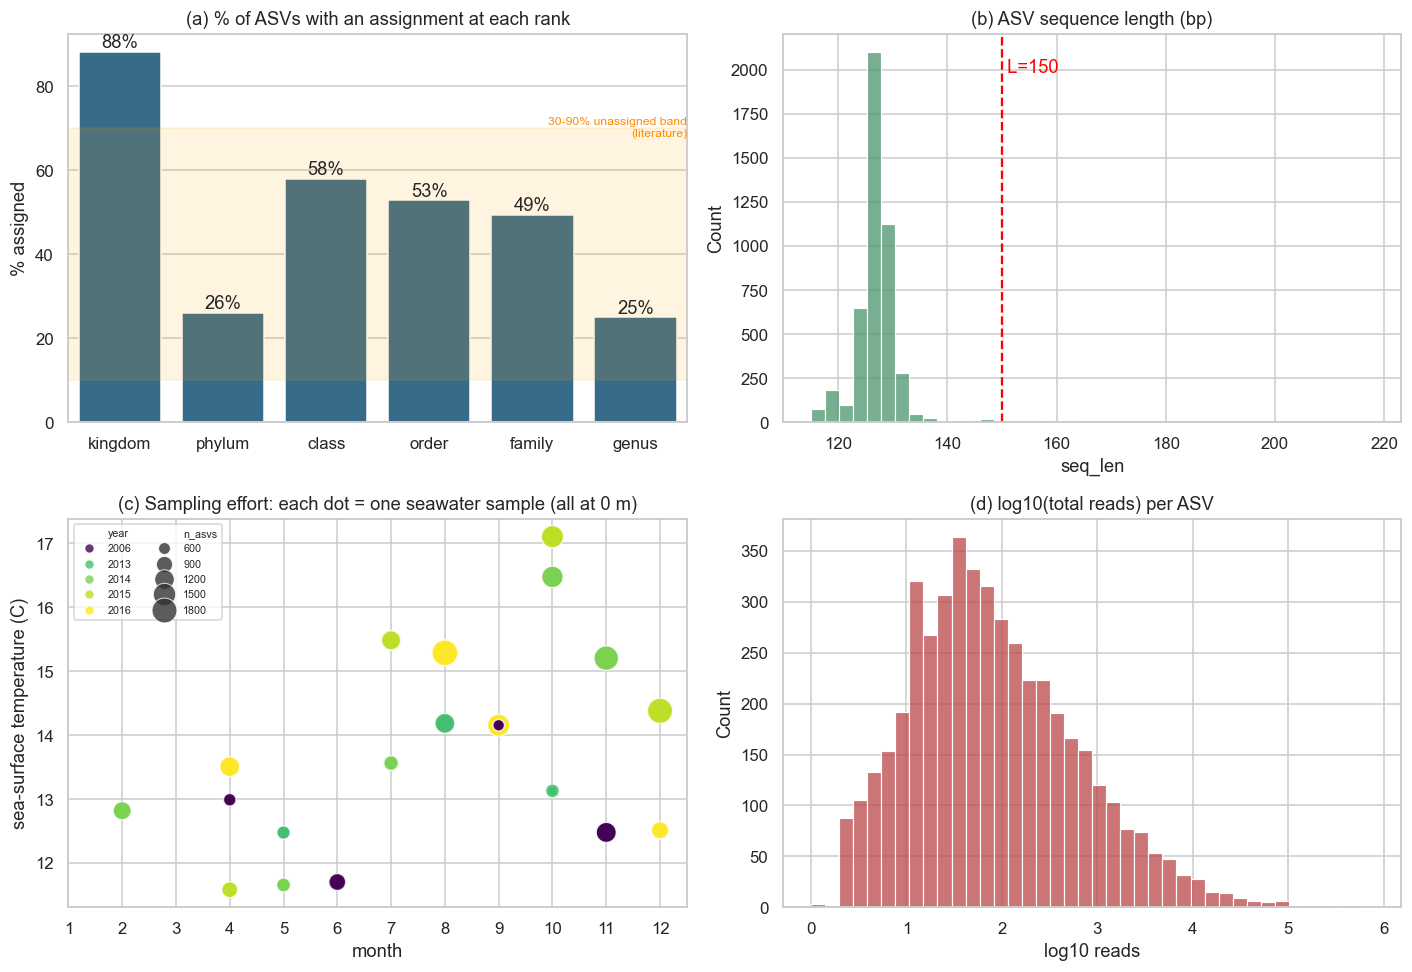

Dark-taxa share (no genus): 75.1%  -> inside the 30-90% band? True
ASVs seen in only ONE sample: 4.9%
Top genera by number of ASVs:


,n_ASVs
genus,
Amoebophrya,199
Akashiwo,71
Protoperidinium,64
Chaetoceros,34
Ensiculifera,31
Pseudo-nitzschia,20
Cryothecomonas,16
Chrysochromulina,16
Karlodinium,15


In [4]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# (a) assignment per rank
ranks = [c for c in ["kingdom","phylum","class","order","family","genus"] if c in taxa_table.columns]
assigned = [taxa_table[c].notna().mean()*100 for c in ranks]
sns.barplot(x=ranks, y=assigned, ax=axes[0,0], color="#2a6f97")
axes[0,0].set_title("(a) % of ASVs with an assignment at each rank"); axes[0,0].set_ylabel("% assigned")
for i,v in enumerate(assigned): axes[0,0].text(i, v+1, f"{v:.0f}%", ha="center")
axes[0,0].axhspan(10, 70, color="orange", alpha=0.12)
axes[0,0].text(len(ranks)-0.5, 68, "30-90% unassigned band\n(literature)", ha="right", fontsize=8, color="darkorange")

# (b) sequence length
sns.histplot(asv_table.seq_len, bins=40, ax=axes[0,1], color="#4c956c")
axes[0,1].axvline(HP["L"], ls="--", color="red"); axes[0,1].text(HP["L"], axes[0,1].get_ylim()[1]*0.9, " L=150", color="red")
axes[0,1].set_title("(b) ASV sequence length (bp)")

# (c) sampling effort: month x temperature (all samples are surface, so temperature replaces depth on the y-axis)
md_ = metadata_table.copy()
sns.scatterplot(data=md_, x="month", y="temp", size="n_asvs", hue="year", palette="viridis",
                sizes=(40, 300), ax=axes[1,0], alpha=0.8)
axes[1,0].set_xticks(range(1,13))
axes[1,0].set_title("(c) Sampling effort: each dot = one seawater sample (all at 0 m)"); axes[1,0].set_ylabel("sea-surface temperature (C)")
axes[1,0].legend(fontsize=7, loc="upper left", ncol=2)

# (d) reads per ASV
sns.histplot(np.log10(asv_table.total_reads), bins=40, ax=axes[1,1], color="#bc4749")
axes[1,1].set_title("(d) log10(total reads) per ASV"); axes[1,1].set_xlabel("log10 reads")
plt.tight_layout(); plt.savefig(OUT_DIR/"fig1_eda.png"); plt.show()

RESULTS["pct_unassigned_genus"] = float((1-taxa_table.assigned_genus.mean())*100)
print(f"Dark-taxa share (no genus): {RESULTS['pct_unassigned_genus']:.1f}%  "
      f"-> inside the 30-90% band? {30 <= RESULTS['pct_unassigned_genus'] <= 90}")
print(f"ASVs seen in only ONE sample: {(asv_table.n_samples==1).mean()*100:.1f}%")
print("Top genera by number of ASVs:"); display(taxa_table.genus.value_counts().head(10).to_frame("n_ASVs"))

## Step 3 - Pre-processing: turning letters and metadata into tensors

**What happens.**
1. **One-hot encoding (slide eq. 1).** Each base becomes a 5-vector: `X[i,c] = 1 if s_i = c else 0`, channels = A, C, G, T, other; sequences are padded / truncated to `L = 150`, giving `X in {0,1}^(150x5)`.
2. **Environment vector (slide eq. 5, extended).** The slide defines `e = [d_min/D, d_max/D, onehot(month)] in R^14`. In this station **every sample is a surface sample (0 m)**, so the two depth slots are constant and carry no information. We therefore keep the slide's 14 slots *and* append the z-scored CTD measurements recorded with each sample (temperature, salinity, chlorophyll), giving `e in R^17`. This is the one deliberate deviation from the slides, and it is forced by the data.
3. **Open-set split of genera.** This is the heart of open-set learning. Genera with at least 3 ASVs are split three ways:
   * **Known (K)** - the model learns to name these.
   * **Hidden-train (U_train)** - "pretend-novel" genera; the model sees their sequences *without labels* during training so the novelty loss can learn `tau0` and `alpha`.
   * **Hidden-val (U_val)** - genera the model **never** sees; used only to pick the best epoch and calibrate decision thresholds. (Calibrating on U_train would cheat: the novelty loss has already pushed those energies up.)
   * **Hidden-test (U_test)** - genera the model **never** sees in any form, reported once at the end. Genera too rare to learn (1-2 ASVs) are split evenly between U_val and U_test. This is the honest test of whether novelty detection generalises to truly new taxa.
4. **Dark set.** All ASVs with no genus at all: these are the real-world unknowns we ultimately want to rank.
5. **Group split by ASV.** Train / validation / test splits are made on *ASV identity*, so no sequence appears on both sides. Otherwise the model could memorise sequences and the test score would be a lie.

**What we predict.** Around 80 genera survive the `min 3 ASVs` filter and roughly 55 become the label space `K`; a few hundred rare genera join the never-seen test set; the dark set is the single largest group of rows.

In [5]:
BASES = {"A":0, "C":1, "G":2, "T":3}
def one_hot(seq, L=HP["L"]):
    x = np.zeros((L, HP["n_channels"]), dtype=np.float32)
    for i, ch in enumerate(seq[:L]):
        x[i, BASES.get(ch, 4)] = 1.0
    return x

D_MAX = float(max(metadata_table.depth_max.max(), 1.0))
EXTRA_MU = metadata_table[ENV_EXTRA].mean(); EXTRA_SD = metadata_table[ENV_EXTRA].std().replace(0, 1.0)
def env_vector(row):
    e = np.zeros(HP["env_dim"], dtype=np.float32)
    e[0] = row.depth_min / D_MAX; e[1] = row.depth_max / D_MAX          # slide slots 0-1
    e[2 + int(row.month) - 1] = 1.0                                     # slide slots 2-13: one-hot month
    for j, c in enumerate(ENV_EXTRA):                                   # extension: z-scored CTD measurements
        e[14 + j] = (getattr(row, c) - EXTRA_MU[c]) / EXTRA_SD[c]
    return e

def density_view(row):
    # Continuous view of e used ONLY by the sampling-density kernel rho(e). One-hot months are all equally far
    # apart, so a kernel on the raw vector could only count replicates of the very same cruise; with a cyclic
    # month and CTD values, "nearby conditions" means neighbouring season and similar water.
    ang = 2*np.pi*(int(row.month)-1)/12
    return np.array([row.depth_min/D_MAX, row.depth_max/D_MAX, np.sin(ang), np.cos(ang)]
                    + [(getattr(row, c) - EXTRA_MU[c]) / EXTRA_SD[c] for c in ENV_EXTRA], dtype=np.float32)
E_DIM = HP["env_dim"]          # ENV[s][:E_DIM] feeds the environment branch, ENV[s][E_DIM:] feeds the density kernel
meta_idx = metadata_table.set_index("sample_id")
ENV = {sid: np.concatenate([env_vector(r), density_view(r)]) for sid, r in meta_idx.iterrows()}
SEQ = dict(zip(asv_table.asv_id, asv_table.sequence))

# ----- instances = (ASV, sample) rows with reads > 0 -----
rows = asv_reads.merge(taxa_table[["asv_id","genus","family"]], on="asv_id", how="left")
rows = rows[rows.sample_id.isin(ENV)].reset_index(drop=True)

# ----- genus split: known / hidden-train / hidden-test -----
genus_counts = taxa_table.dropna(subset=["genus"]).genus.value_counts()
eligible = sorted(genus_counts[genus_counts >= HP["min_asv_per_genus"]].index)
rng = np.random.RandomState(SEED); rng.shuffle(eligible)
n_hid = max(3, int(0.30 * len(eligible)))
hidden_train = set(eligible[:n_hid//2])                       # seen WITHOUT labels during training (novelty loss)
held = eligible[n_hid//2:n_hid]
hidden_val   = set(held[:len(held)//2])                       # never seen: threshold calibration + model selection
hidden_test  = set(held[len(held)//2:])                       # never seen: final evaluation only
known        = set(eligible[n_hid:])
rare = sorted(genus_counts[genus_counts < HP["min_asv_per_genus"]].index)   # 1-2 ASVs: too thin to learn, never seen
rng.shuffle(rare)
hidden_val  |= set(rare[:len(rare)//2]); hidden_test |= set(rare[len(rare)//2:])
GENERA = sorted(known); G2I = {g:i for i,g in enumerate(GENERA)}; K = len(GENERA)

def group_of(g):
    if pd.isna(g): return "dark"
    if g in known: return "known"
    if g in hidden_train: return "hidden_train"
    if g in hidden_val: return "hidden_val"
    return "hidden_test"
rows["group"] = rows.genus.map(group_of)

# ----- split KNOWN rows by ASV identity -----
kn = rows[rows.group=="known"].reset_index(drop=True)
gss = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=SEED)
tr_i, tmp_i = next(gss.split(kn, groups=kn.asv_id))
tmp = kn.iloc[tmp_i]
gss2 = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=SEED)
va_i, te_i = next(gss2.split(tmp, groups=tmp.asv_id))
train_df, val_df, test_df = kn.iloc[tr_i].copy(), tmp.iloc[va_i].copy(), tmp.iloc[te_i].copy()
# keep only genera that actually occur in train (tiny genera may fall entirely into val/test)
seen = set(train_df.genus)
val_df, test_df = val_df[val_df.genus.isin(seen)], test_df[test_df.genus.isin(seen)]
GENERA = sorted(seen); G2I = {g:i for i,g in enumerate(GENERA)}; K = len(GENERA)

utrain_df = rows[rows.group=="hidden_train"].copy()
uval_df   = rows[rows.group=="hidden_val"].copy()
utest_df  = rows[rows.group=="hidden_test"].copy()
dark_df   = rows[rows.group=="dark"].copy()

class EDNADataset(torch.utils.data.Dataset):
    def __init__(self, frame, with_label=True):
        self.f = frame.reset_index(drop=True); self.with_label = with_label
        self.X = torch.tensor(np.stack([one_hot(SEQ[a]) for a in self.f.asv_id]))
        self.E = torch.tensor(np.stack([ENV[s] for s in self.f.sample_id]))
        self.y = torch.tensor([G2I.get(g, -1) for g in self.f.genus], dtype=torch.long)
    def __len__(self): return len(self.f)
    def __getitem__(self, i): return self.X[i], self.E[i], self.y[i]

def loader(frame, shuffle, bs=HP["batch_size"]):
    return torch.utils.data.DataLoader(EDNADataset(frame), batch_size=bs, shuffle=shuffle)

summary = pd.DataFrame({
    "split": ["train (known)", "val (known)", "test (known)", "hidden-train U_train (seen, unlabelled)", "hidden-val U_val (never seen)", "hidden-test U_test (never seen)", "dark (no genus)"],
    "rows":  [len(d) for d in (train_df, val_df, test_df, utrain_df, uval_df, utest_df, dark_df)],
    "ASVs":  [d.asv_id.nunique() for d in (train_df, val_df, test_df, utrain_df, uval_df, utest_df, dark_df)],
    "genera":[d.genus.nunique() for d in (train_df, val_df, test_df, utrain_df, uval_df, utest_df)] + [0],
})
RESULTS["K"] = K; RESULTS["n_hidden_train"] = len(hidden_train); RESULTS["n_hidden_val"] = len(hidden_val); RESULTS["n_hidden_test"] = len(hidden_test)
print(f"Learnable genera K = {K} | hidden-train = {len(hidden_train)} genera | hidden-val = {len(hidden_val)} genera | hidden-test = {len(hidden_test)} genera (held-out + rare, never seen)")
print(f"Env vector dim = {HP['env_dim']} (+{len(next(iter(ENV.values())))-E_DIM} continuous slots for the density kernel)  (D = {D_MAX:.0f} m)   | one-hot shape = {one_hot(next(iter(SEQ.values()))).shape}")
display(summary)

Learnable genera K = 54 | hidden-train = 11 genera | hidden-val = 129 genera | hidden-test = 129 genera (held-out + rare, never seen)
Env vector dim = 17 (+7 continuous slots for the density kernel)  (D = 1 m)   | one-hot shape = (150, 5)


,split,rows,ASVs,genera
0,train (known),6174,339,54
1,val (known),1404,73,36
2,test (known),1358,70,33
3,"hidden-train U_train (seen, unlabelled)",5435,307,11
4,hidden-val U_val (never seen),3329,187,129
5,hidden-test U_test (never seen),2896,187,129
6,dark (no genus),44249,3508,0


## Step 4 - The model: two branches, a fusion block, two heads

**What happens.** We build the network exactly as drawn in the proposed design.

**Sequence branch (slide eqs. 2-4)**
```
h_k = ReLU(W_k * X + b_k)        k in {3,5,7}, 64 filters each
g_k[j] = max_i h_k[i, j]         global max-pool: keep each pattern's best hit  -> 64
g = [g3 || g5 || g7]             -> 192
z_s = W_s . g + b_s              -> 128   (the DNA fingerprint)
```
**Environment branch (slide eqs. 5-6)**
```
h_e = ReLU(W1 . e + b1)          14 -> 64
z_e = W2 . h_e + b2              64 -> 128 (the context fingerprint)
```
**Fusion (slide eq. 7)**
```
u = [z_s || z_e]                 -> 256
z = Dropout(ReLU(W_f . u + b_f)) -> 256
```
**Classification head (slide eqs. 8-11)**: logits `f(z) = W_c z + b_c in R^K`, softmax `p_k`, prediction `argmax_k p_k`, cross-entropy `L_cls`.

**Novelty head (slide eqs. 12-16)**
* Energy `E = -log sum_k exp(f_k)`: the "shrug meter". Confident -> very negative; no genus scored strongly -> high.
* Sampling density `rho(e)`: kernel-smoothed fraction of training *water samples* whose conditions lie near `e`. (Slide eq. 13 is the hard-count version; we use a Gaussian kernel on a continuous view of `e` with cyclic month and CTD values, so neighbouring seasons and similar water count as "nearby".)
* Adaptive threshold `tau(e) = tau0 + alpha . log rho(e)` with **learnable** `tau0`, `alpha`.
* Decision `novel = 1 if E > tau(e)`.
* Hinge novelty loss `L_novel = mean_K max(0, E - tau + m) + mean_U max(0, tau - E + m)`.
* Total `L = L_cls + 0.5 . L_novel`.

**What we predict.** About 150 k trainable parameters. Because `log rho <= 0`, and rarely-sampled conditions should get a *lenient* (higher) cutoff, we predict the learned **`alpha` will be negative**.

In [6]:
class SeqBranch(nn.Module):
    def __init__(self, in_ch=HP["n_channels"], nf=HP["conv_filters"], ks=HP["kernel_sizes"], out=HP["z_dim"]):
        super().__init__()
        self.convs = nn.ModuleList([nn.Conv1d(in_ch, nf, k, padding=k//2) for k in ks])
        self.fc = nn.Linear(nf*len(ks), out)
    def forward(self, X):                       # X: (B, L, 5)
        x = X.transpose(1, 2)                   # (B, 5, L)
        g = torch.cat([F.relu(c(x)).amax(dim=2) for c in self.convs], dim=1)   # (B, 192)
        return self.fc(g)                       # z_s: (B, 128)

class EnvBranch(nn.Module):
    def __init__(self, inp=HP["env_dim"], hid=64, out=HP["z_dim"]):
        super().__init__()
        self.fc1, self.fc2 = nn.Linear(inp, hid), nn.Linear(hid, out)
    def forward(self, e): return self.fc2(F.relu(self.fc1(e)))    # z_e: (B, 128)

class ContextAwareOpenSetNet(nn.Module):
    def __init__(self, K, use_env=True):
        super().__init__()
        self.use_env = use_env
        self.seq, self.env = SeqBranch(), EnvBranch()
        self.fuse = nn.Sequential(nn.Linear(2*HP["z_dim"], HP["fusion_dim"]), nn.ReLU(), nn.Dropout(HP["dropout"]))
        self.cls  = nn.Linear(HP["fusion_dim"], K)
        self.tau0  = nn.Parameter(torch.tensor(0.0))     # learnable base threshold
        self.alpha = nn.Parameter(torch.tensor(0.0))     # learnable density sensitivity
    def embed(self, X, e):
        z_s = self.seq(X); z_e = self.env(e[:, :E_DIM])
        if not self.use_env: z_e = torch.zeros_like(z_e)  # ablation: switch context off
        return self.fuse(torch.cat([z_s, z_e], dim=1))
    def forward(self, X, e, log_rho):
        z = self.embed(X, e)
        logits = self.cls(z)
        energy = -torch.logsumexp(logits, dim=1)          # eq. 12
        tau    = self.tau0 + self.alpha * log_rho         # eq. 14
        return logits, energy, tau, z

# ---------------- sampling density rho(e) (eq. 13, kernel version) ----------------
# rho is a fraction over *samples* (one vector per water sample seen in training), not over ASV rows,
# so a species-rich sample does not count as "more explored" than a species-poor one.
TRAIN_ENV = torch.tensor(np.stack([ENV[s][E_DIM:] for s in sorted(train_df.sample_id.unique())]))
def log_density(e, bw=HP["density_bw"]):
    # e: (B, env_dim + density slots). rho = mean_i exp(-||v_i - v||^2 / 2 bw^2)  in (0, 1], v = continuous view
    d2 = torch.cdist(e[:, E_DIM:], TRAIN_ENV.to(e.device)).pow(2)
    rho = torch.exp(-d2 / (2*bw*bw)).mean(dim=1).clamp_min(1e-6)
    return torch.log(rho)

def novelty_loss(E_known, tau_known, E_unknown, tau_unknown, m=HP["margin"]):
    l_k = F.relu(E_known - tau_known + m).mean() if len(E_known) else torch.tensor(0.0)
    l_u = F.relu(tau_unknown - E_unknown + m).mean() if len(E_unknown) else torch.tensor(0.0)
    return l_k + l_u

model = ContextAwareOpenSetNet(K).to(DEVICE)
n_params = sum(p.numel() for p in model.parameters())
print(model); print(f"\nTrainable parameters: {n_params:,}")
RESULTS["n_params"] = n_params

# sanity: one forward pass
Xb, Eb, yb = next(iter(loader(train_df.head(8), False)))
lg, en, ta, zz = model(Xb.to(DEVICE), Eb.to(DEVICE), log_density(Eb.to(DEVICE)))
print("logits", tuple(lg.shape), "| energy", tuple(en.shape), "| tau", tuple(ta.shape), "| z", tuple(zz.shape))

ContextAwareOpenSetNet(
  (seq): SeqBranch(
    (convs): ModuleList(
      (0): Conv1d(5, 64, kernel_size=(3,), stride=(1,), padding=(1,))
      (1): Conv1d(5, 64, kernel_size=(5,), stride=(1,), padding=(2,))
      (2): Conv1d(5, 64, kernel_size=(7,), stride=(1,), padding=(3,))
    )
    (fc): Linear(in_features=192, out_features=128, bias=True)
  )
  (env): EnvBranch(
    (fc1): Linear(in_features=17, out_features=64, bias=True)
    (fc2): Linear(in_features=64, out_features=128, bias=True)
  )
  (fuse): Sequential(
    (0): Linear(in_features=256, out_features=256, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
  )
  (cls): Linear(in_features=256, out_features=54, bias=True)
)

Trainable parameters: 118,840
logits (8, 54) | energy (8,) | tau (8,) | z (8, 256)


## Step 5 - Training: name the known, push the hidden over the line

**What happens.** Each epoch alternates mini-batches of **known** rows (labelled, drive `L_cls` and the known side of `L_novel`) with mini-batches of **hidden-train** rows (unlabelled, drive the unknown side of `L_novel`). Adam optimiser with weight decay; the two threshold scalars `tau0`, `alpha` get a 20x larger learning rate because otherwise the (much bigger) network satisfies the hinge by moving energies before the threshold has moved at all. We keep the checkpoint with the best validation score = genus accuracy on known-val + AUROC of energy for known-val vs **hidden-val** (never-seen genera).

We train **two** models with identical seeds and schedule:
* **Full model** (sequence + environment + adaptive threshold): the proposed design.
* **Sequence-only ablation** (environment branch zeroed): the literature baseline. We need it later for Hypothesis H2.

**What we predict.**
* `L_cls` falls steadily; validation genus accuracy climbs to roughly 80-85 % and plateaus after about 25 epochs (BarcodeBERT / DeepBarcoding-level performance on clean barcodes is 90 %+, our 18S V9 amplicon is shorter and noisier and several genera have only 3-5 training ASVs).
* Energy of known rows drifts strongly negative; energy of hidden rows stays higher; the gap widens as `L_novel` works.
* The full model edges out the sequence-only model on validation accuracy, because depth / season tell the model which genera are plausible.

In [7]:
def run_epoch(model, opt, known_loader, unknown_loader, train=True):
    model.train(train)
    tot = Counter(); n = 0
    unk_iter = iter(unknown_loader) if unknown_loader is not None else None
    for X, e, y in known_loader:
        X, e, y = X.to(DEVICE), e.to(DEVICE), y.to(DEVICE)
        with torch.set_grad_enabled(train):
            logits, E_k, tau_k, _ = model(X, e, log_density(e))
            l_cls = F.cross_entropy(logits, y)
            E_u = tau_u = torch.tensor([], device=DEVICE)
            if unk_iter is not None:
                try: Xu, eu, _ = next(unk_iter)
                except StopIteration:
                    unk_iter = iter(unknown_loader); Xu, eu, _ = next(unk_iter)
                Xu, eu = Xu.to(DEVICE), eu.to(DEVICE)
                _, E_u, tau_u, _ = model(Xu, eu, log_density(eu))
            l_nov = novelty_loss(E_k, tau_k, E_u, tau_u)
            loss = l_cls + HP["lambda_novel"] * l_nov
            if train:
                opt.zero_grad(); loss.backward(); opt.step()
        b = len(y); n += b
        tot["loss"] += loss.item()*b; tot["l_cls"] += l_cls.item()*b; tot["l_nov"] += l_nov.item()*b
        tot["acc"] += (logits.argmax(1)==y).float().sum().item()
    return {k: v/n for k, v in tot.items()}

@torch.no_grad()
def predict(model, frame, bs=1024):
    # returns dict of numpy arrays for any frame (labels may be -1)
    model.eval(); out = defaultdict(list)
    for X, e, y in loader(frame, False, bs):
        X, e = X.to(DEVICE), e.to(DEVICE)
        lr_ = log_density(e)
        logits, E, tau, z = model(X, e, lr_)
        p = F.softmax(logits, 1)
        out["pred"].append(logits.argmax(1).cpu()); out["maxprob"].append(p.max(1).values.cpu())
        out["energy"].append(E.cpu()); out["tau"].append(tau.cpu()); out["log_rho"].append(lr_.cpu())
        out["z"].append(z.cpu()); out["y"].append(y)
        out["top3"].append(logits.topk(3, dim=1).indices.cpu())
    return {k: torch.cat(v).numpy() for k, v in out.items()}

def open_set_auroc(model, known_frame, unknown_frame):
    pk, pu = predict(model, known_frame), predict(model, unknown_frame)
    y = np.r_[np.zeros(len(pk["energy"])), np.ones(len(pu["energy"]))]
    return roc_auc_score(y, np.r_[pk["energy"], pu["energy"]]), accuracy_score(pk["y"], pk["pred"])

def train_model(use_env, tag, seed=SEED, verbose=True):
    seed_everything(seed)
    m = ContextAwareOpenSetNet(K, use_env=use_env).to(DEVICE)
    net_params = [p for n, p in m.named_parameters() if n not in ("tau0", "alpha")]
    opt = torch.optim.Adam([{"params": net_params},
                            {"params": [m.tau0, m.alpha], "lr": HP["lr"]*HP["thr_lr_mult"], "weight_decay": 0.0}],
                           lr=HP["lr"], weight_decay=HP["weight_decay"])
    kl, ul = loader(train_df, True), loader(utrain_df, True)
    hist, best, best_state = [], -1, None
    t0 = time.time()
    for ep in range(1, HP["epochs"]+1):
        tr = run_epoch(m, opt, kl, ul, train=True)
        auroc, vacc = open_set_auroc(m, val_df, uval_df)     # model selection on NEVER-SEEN hidden-val genera
        score = vacc + auroc
        hist.append(dict(epoch=ep, **tr, val_acc=vacc, val_auroc=auroc, tau0=m.tau0.item(), alpha=m.alpha.item()))
        if score > best: best, best_state = score, {k: v.clone() for k, v in m.state_dict().items()}
        if verbose and (ep <= 3 or ep % 5 == 0 or ep == HP["epochs"]):
            print(f"[{tag}] ep {ep:02d} | loss {tr['loss']:.3f} (cls {tr['l_cls']:.3f}, nov {tr['l_nov']:.3f}) "
                  f"| train acc {tr['acc']:.3f} | val acc {vacc:.3f} | val AUROC(never-seen) {auroc:.3f} "
                  f"| tau0 {m.tau0.item():+.2f} alpha {m.alpha.item():+.2f} | {time.time()-t0:5.0f}s")
    m.load_state_dict(best_state)
    return m, pd.DataFrame(hist)

model, hist = train_model(use_env=True,  tag="FULL   ")
model_seq, hist_seq = train_model(use_env=False, tag="SEQ-ONLY")
torch.save(model.state_dict(), OUT_DIR/"model_full.pt"); torch.save(model_seq.state_dict(), OUT_DIR/"model_seqonly.pt")
hist.to_csv(OUT_DIR/"history_full.csv", index=False); hist_seq.to_csv(OUT_DIR/"history_seqonly.csv", index=False)
RESULTS["tau0"], RESULTS["alpha"] = model.tau0.item(), model.alpha.item()
print(f"\nLearned threshold parameters: tau0 = {RESULTS['tau0']:+.3f}, alpha = {RESULTS['alpha']:+.3f} "
      f"-> prediction 'alpha < 0' {'CONFIRMED' if RESULTS['alpha'] < 0 else 'NOT confirmed'}")

[FULL   ] ep 01 | loss 5.395 (cls 3.615, nov 3.560) | train acc 0.121 | val acc 0.109 | val AUROC(never-seen) 0.446 | tau0 -0.48 alpha +0.48 |     4s


[FULL   ] ep 02 | loss 4.480 (cls 3.495, nov 1.970) | train acc 0.141 | val acc 0.103 | val AUROC(never-seen) 0.458 | tau0 -0.60 alpha +0.60 |     8s


[FULL   ] ep 03 | loss 4.329 (cls 3.369, nov 1.921) | train acc 0.177 | val acc 0.147 | val AUROC(never-seen) 0.500 | tau0 -0.61 alpha +0.61 |    12s


[FULL   ] ep 05 | loss 3.138 (cls 2.553, nov 1.170) | train acc 0.371 | val acc 0.235 | val AUROC(never-seen) 0.579 | tau0 -0.61 alpha +0.59 |    18s


[FULL   ] ep 10 | loss 1.240 (cls 1.089, nov 0.302) | train acc 0.698 | val acc 0.572 | val AUROC(never-seen) 0.743 | tau0 -0.44 alpha +0.37 |    33s


...

[SEQ-ONLY] ep 20 | loss 0.212 (cls 0.176, nov 0.074) | train acc 0.965 | val acc 0.747 | val AUROC(never-seen) 0.750 | tau0 -0.42 alpha +0.30 |    51s


[SEQ-ONLY] ep 25 | loss 0.111 (cls 0.090, nov 0.042) | train acc 0.987 | val acc 0.768 | val AUROC(never-seen) 0.750 | tau0 -0.40 alpha +0.26 |    65s


[SEQ-ONLY] ep 30 | loss 0.062 (cls 0.052, nov 0.021) | train acc 0.993 | val acc 0.815 | val AUROC(never-seen) 0.771 | tau0 -0.39 alpha +0.25 |    78s


[SEQ-ONLY] ep 35 | loss 0.037 (cls 0.031, nov 0.012) | train acc 0.997 | val acc 0.820 | val AUROC(never-seen) 0.771 | tau0 -0.38 alpha +0.24 |    91s


[SEQ-ONLY] ep 40 | loss 0.031 (cls 0.026, nov 0.010) | train acc 0.996 | val acc 0.789 | val AUROC(never-seen) 0.768 | tau0 -0.37 alpha +0.23 |   105s

Learned threshold parameters: tau0 = -0.312, alpha = +0.216 -> prediction 'alpha < 0' NOT confirmed


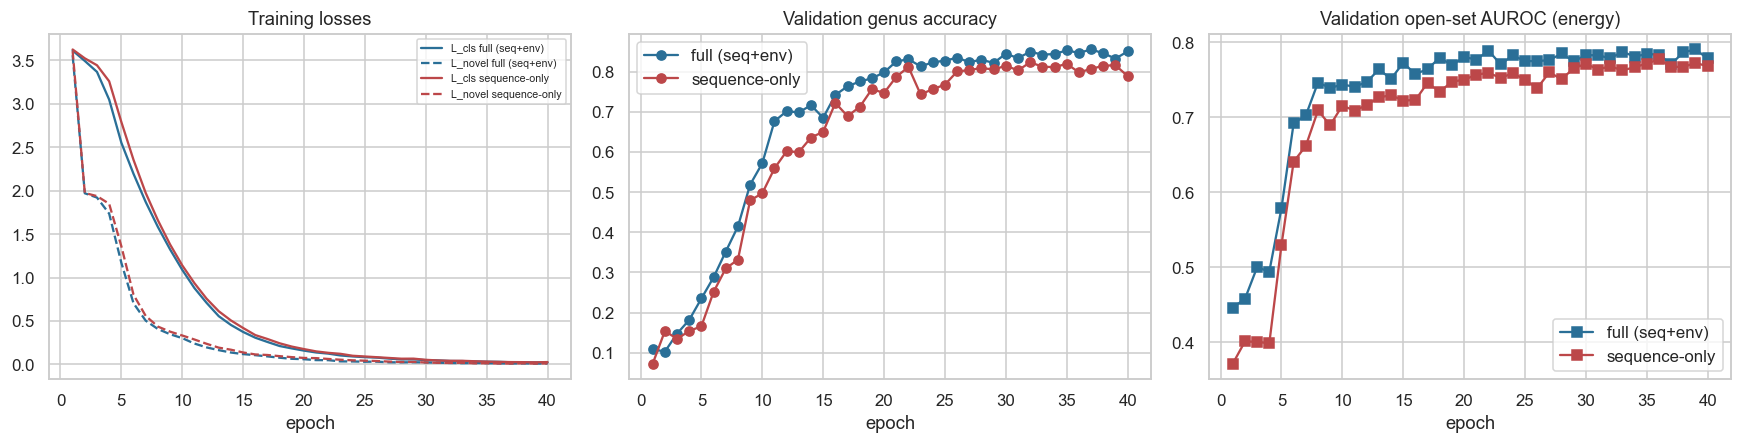

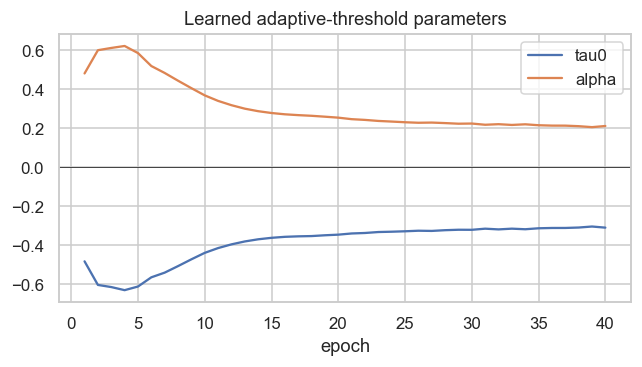

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for h, lab, c in [(hist, "full (seq+env)", "#2a6f97"), (hist_seq, "sequence-only", "#bc4749")]:
    axes[0].plot(h.epoch, h.l_cls, color=c, label=f"L_cls {lab}"); axes[0].plot(h.epoch, h.l_nov, color=c, ls="--", label=f"L_novel {lab}")
    axes[1].plot(h.epoch, h.val_acc, color=c, marker="o", label=lab)
    axes[2].plot(h.epoch, h.val_auroc, color=c, marker="s", label=lab)
axes[0].set_title("Training losses"); axes[0].legend(fontsize=7)
axes[1].set_title("Validation genus accuracy"); axes[1].legend()
axes[2].set_title("Validation open-set AUROC (energy)"); axes[2].legend()
for a in axes: a.set_xlabel("epoch")
plt.tight_layout(); plt.savefig(OUT_DIR/"fig2_training.png"); plt.show()

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(hist.epoch, hist.tau0, label="tau0"); ax.plot(hist.epoch, hist.alpha, label="alpha")
ax.axhline(0, color="k", lw=0.5); ax.set_title("Learned adaptive-threshold parameters"); ax.legend(); ax.set_xlabel("epoch")
plt.tight_layout(); plt.savefig(OUT_DIR/"fig2b_threshold_params.png"); plt.show()

## Step 6 - Evaluation: how well do we name, and how well do we shrug?

**What happens.** On the held-out **test** split (known genera, unseen ASVs) and on **hidden-test** genera (never seen during training in any form) we measure:

*Closed-set (output 1, "names the organism")*
* Top-1 and Top-3 genus accuracy, macro-F1.
* Family-level accuracy derived from the predicted genus (the slide argues higher-rank calls remain useful when species references are missing).

*Open-set (output 2, "decides if it is new")*
* **AUROC** of the energy score for separating known-test vs hidden-test rows: a threshold-free measure of the shrug meter. We report it twice: against *known unknowns* (new ASVs of the hidden-train genera the loss was trained on) and against *unknown unknowns* (hidden-test genera never seen). The second number is the one that matters.
* **FPR @ 95 % TPR**: how many known ASVs we would wrongly flag while catching 95 % of novel ones.
* **Decision rules.** Novel rows outnumber known test rows by about 7 to 1, so plain F1 rewards a rule that flags everything. Our primary metric is therefore **balanced accuracy** (mean of novel-catch rate and known-keep rate), with **MCC** and F1 alongside. Four rules, all tuned on **known-val vs hidden-val** (never-seen genera), evaluated on known-test vs hidden-test:
  1. **Adaptive threshold, as learned** `E > tau(e)` with `tau0`, `alpha` straight from the hinge loss (ours, raw).
  2. **Adaptive threshold, calibrated** `E > tau0 + delta + (alpha + a) . log rho(e)`: the offset and the density slope are re-fitted on validation. This is the exploration-aware rule given a fair chance.
  3. **Fixed threshold** `E > tau_fixed`, tuned on the same validation data with the slope forced to zero (the exploration-blind version). Rules 2 and 3 differ *only* in the `log rho(e)` term.
  4. **Max-softmax-probability (MSP)** baseline `max_k p_k < t`, the classic uncertainty rule the slides criticise ("always returns a best-guess label").

**What we predict.** Genus accuracy on never-seen ASVs well above the 1/K chance level, in the 70-90 % range (18S V9 is a short, low-resolution marker and many genera have only a handful of training ASVs). Open-set AUROC near 1.0 for known unknowns and clearly above 0.8 for unknown unknowns. Energy beats MSP. The calibrated adaptive rule matches or beats the fixed rule on balanced accuracy; how much it adds depends on how much sampling effort actually varies at this single station.

CLOSED-SET  | genus top-1 0.744 | top-3 0.867 | macro-F1 0.688 | family acc 0.727
OPEN-SET    | energy AUROC: known-unknowns 1.000 | unknown-unknowns 0.774 | MSP (unknown-unknowns) 0.757 | FPR@95%TPR 0.679


Calibrated rule: novel if E > -2.61 +0.12 * log rho(e)   (log rho spans [-2.98, -1.89] -> the threshold moves by up to 0.13 energy units across sampling conditions)
Calibrated slope sign: POSITIVE (stricter where rarely sampled) - opposite to prediction
MSP baseline AUROC 0.757  (energy AUROC 0.774)


,balanced_acc,mcc,f1,precision,recall,known_flag_rate,novel_catch_rate
"Adaptive tau(e), as learned [ours]",0.657,0.324,0.543,0.919,0.386,0.072,0.386
Adaptive tau(e) calibrated: -2.61 +0.12 log rho [ours],0.676,0.335,0.642,0.874,0.507,0.156,0.507
Fixed tau = -2.80,0.670,0.326,0.632,0.872,0.496,0.155,0.496
MSP < 0.914,0.706,0.418,0.819,0.809,0.829,0.417,0.829


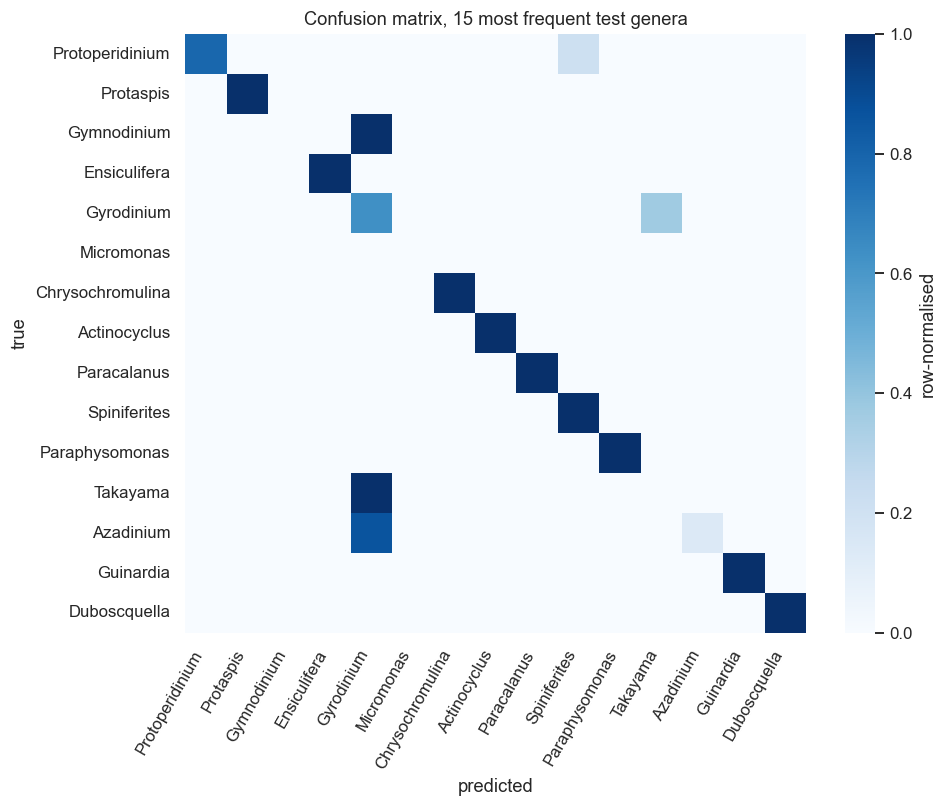

In [9]:
P_te  = predict(model, test_df)      # known genera, unseen ASVs
P_ut  = predict(model, utest_df)     # hidden-test genera, never seen
P_va  = predict(model, val_df)       # known genera, validation ASVs
P_uv  = predict(model, uval_df)      # hidden-val genera, never seen (calibration only)
P_utr = predict(model, utrain_df)    # hidden-train genera ("known unknowns")

# ---- closed-set ----
top1 = accuracy_score(P_te["y"], P_te["pred"])
top3 = np.mean([y in t for y, t in zip(P_te["y"], P_te["top3"])])
macro_f1 = f1_score(P_te["y"], P_te["pred"], average="macro")
g2f = taxa_table.dropna(subset=["genus"]).drop_duplicates("genus").set_index("genus")["family"].to_dict() if "family" in taxa_table.columns else {}
fam_true = [g2f.get(GENERA[y]) for y in P_te["y"]]; fam_pred = [g2f.get(GENERA[p]) for p in P_te["pred"]]
fam_acc = np.mean([a==b and a is not None for a, b in zip(fam_true, fam_pred)])
RESULTS.update(top1=top1, top3=top3, macro_f1=macro_f1, family_acc=fam_acc)
print(f"CLOSED-SET  | genus top-1 {top1:.3f} | top-3 {top3:.3f} | macro-F1 {macro_f1:.3f} | family acc {fam_acc:.3f}")

# ---- open-set: threshold-free ----
def os_arrays(Pk, Pu, key="energy", sign=1.0):
    return np.r_[np.zeros(len(Pk[key])), np.ones(len(Pu[key]))], sign*np.r_[Pk[key], Pu[key]]
y_os, E_os = os_arrays(P_te, P_ut)
auroc = roc_auc_score(y_os, E_os)
fpr, tpr, thr = roc_curve(y_os, E_os); fpr95 = float(fpr[np.searchsorted(tpr, 0.95)])
auroc_ku  = roc_auc_score(*os_arrays(P_te, P_utr))                    # known unknowns (trained-on genera, new ASVs)
msp_auroc = roc_auc_score(*os_arrays(P_te, P_ut, "maxprob", -1.0))
RESULTS.update(auroc=auroc, auroc_known_unknown=auroc_ku, fpr95=fpr95, msp_auroc=msp_auroc)
print(f"OPEN-SET    | energy AUROC: known-unknowns {auroc_ku:.3f} | unknown-unknowns {auroc:.3f} | MSP (unknown-unknowns) {msp_auroc:.3f} | FPR@95%TPR {fpr95:.3f}")

# ---- decision rules ----
def metrics(flag_known, flag_unknown):
    fk, fu = np.asarray(flag_known, bool), np.asarray(flag_unknown, bool)
    tp, fn, fp, tn = fu.sum(), (~fu).sum(), fk.sum(), (~fk).sum()
    prec = tp/(tp+fp) if tp+fp else 0.0; rec = tp/(tp+fn); tnr = tn/(tn+fp)
    f1 = 2*prec*rec/(prec+rec) if prec+rec else 0.0
    den = math.sqrt(float((tp+fp)*(tp+fn)*(tn+fp)*(tn+fn))); mcc = (tp*tn - fp*fn)/den if den else 0.0
    return dict(balanced_acc=(rec+tnr)/2, mcc=mcc, f1=f1, precision=prec, recall=rec,
                known_flag_rate=fk.mean(), novel_catch_rate=fu.mean())
OBJ = "balanced_acc"
def tau_of(P, delta=0.0, a=0.0): return P["tau"] + delta + a*P["log_rho"]   # tau0 + alpha log rho  (+ delta + a log rho)

def calibrate(Pva, Puv):
    # All thresholds are tuned on known-val vs hidden-val (never-seen genera), never on anything used in training.
    deltas, slopes = np.linspace(-12, 12, 241), np.linspace(-4, 4, 81)
    _, delta, a = max((metrics(Pva["energy"] > tau_of(Pva, d, a), Puv["energy"] > tau_of(Puv, d, a))[OBJ], d, a)
                      for d in deltas for a in slopes)
    cands = np.quantile(np.r_[Pva["energy"], Puv["energy"]], np.linspace(0.005, 0.995, 397))
    t_fixed = float(max(cands, key=lambda t: metrics(Pva["energy"] > t, Puv["energy"] > t)[OBJ]))
    cands_p = np.quantile(np.r_[Pva["maxprob"], Puv["maxprob"]], np.linspace(0.005, 0.995, 397))
    t_msp = float(max(cands_p, key=lambda t: metrics(Pva["maxprob"] < t, Puv["maxprob"] < t)[OBJ]))
    return float(delta), float(a), t_fixed, t_msp

DELTA, ALPHA_CAL, tau_fixed, t_msp = calibrate(P_va, P_uv)
ALPHA_TOTAL = RESULTS["alpha"] + ALPHA_CAL
def tau_cal(P, delta=None, a=None): return tau_of(P, DELTA if delta is None else delta, ALPHA_CAL if a is None else a)

# 1) adaptive, exactly as learned by the hinge loss
adaptive_raw = metrics(P_te["energy"] > P_te["tau"], P_ut["energy"] > P_ut["tau"])
# 2) adaptive, offset AND slope re-fitted on validation
adaptive = metrics(P_te["energy"] > tau_cal(P_te), P_ut["energy"] > tau_cal(P_ut))
# 3) fixed threshold (slope forced to 0) tuned on the same validation data
fixed = metrics(P_te["energy"] > tau_fixed, P_ut["energy"] > tau_fixed)
# 4) MSP baseline tuned on validation
msp = metrics(P_te["maxprob"] < t_msp, P_ut["maxprob"] < t_msp)

rules = pd.DataFrame([adaptive_raw, adaptive, fixed, msp],
                     index=["Adaptive tau(e), as learned [ours]",
                            f"Adaptive tau(e) calibrated: {RESULTS['tau0']+DELTA:.2f} {ALPHA_TOTAL:+.2f} log rho [ours]",
                            f"Fixed tau = {tau_fixed:.2f}", f"MSP < {t_msp:.3f}"]).round(3)
RESULTS["novelty_rules"] = rules.to_dict(); RESULTS["tau_fixed"] = tau_fixed
RESULTS["delta"] = float(DELTA); RESULTS["alpha_cal"] = float(ALPHA_CAL); RESULTS["alpha_total"] = float(ALPHA_TOTAL)
lr_range = (float(np.r_[P_te["log_rho"], P_ut["log_rho"]].min()), float(np.r_[P_te["log_rho"], P_ut["log_rho"]].max()))
RESULTS["log_rho_range"] = lr_range
print(f"Calibrated rule: novel if E > {RESULTS['tau0']+DELTA:.2f} {ALPHA_TOTAL:+.2f} * log rho(e)   "
      f"(log rho spans [{lr_range[0]:.2f}, {lr_range[1]:.2f}] -> the threshold moves by up to {abs(ALPHA_TOTAL*(lr_range[1]-lr_range[0])):.2f} energy units across sampling conditions)")
print(f"Calibrated slope sign: {'NEGATIVE (lenient where rarely sampled) - as predicted' if ALPHA_TOTAL < 0 else 'POSITIVE (stricter where rarely sampled) - opposite to prediction'}")
print(f"MSP baseline AUROC {msp_auroc:.3f}  (energy AUROC {auroc:.3f})")
display(rules)

# ---- confusion matrix for the 15 most common test genera ----
top_g = pd.Series(P_te["y"]).value_counts().head(15).index
mask = np.isin(P_te["y"], top_g)
cm = confusion_matrix(P_te["y"][mask], P_te["pred"][mask], labels=top_g, normalize="true")
fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(cm, xticklabels=[GENERA[i] for i in top_g], yticklabels=[GENERA[i] for i in top_g], cmap="Blues", ax=ax, cbar_kws={"label":"row-normalised"})
ax.set_title("Confusion matrix, 15 most frequent test genera"); ax.set_xlabel("predicted"); ax.set_ylabel("true")
plt.xticks(rotation=60, ha="right"); plt.tight_layout(); plt.savefig(OUT_DIR/"fig3_confusion.png"); plt.show()

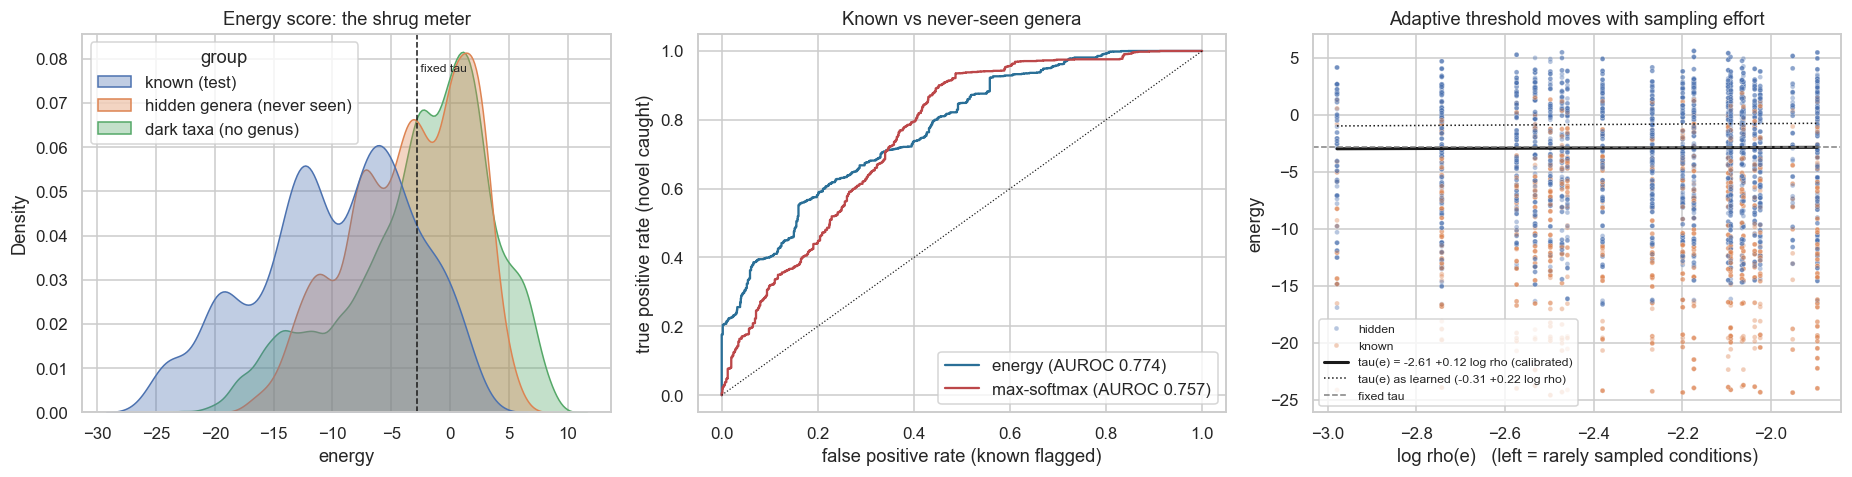

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
# energy distributions
P_dark = predict(model, dark_df)
dd = pd.concat([pd.DataFrame({"energy": P_te["energy"], "group": "known (test)"}),
                pd.DataFrame({"energy": P_ut["energy"], "group": "hidden genera (never seen)"}),
                pd.DataFrame({"energy": P_dark["energy"], "group": "dark taxa (no genus)"})])
sns.kdeplot(data=dd, x="energy", hue="group", fill=True, common_norm=False, ax=axes[0], alpha=0.35)
axes[0].axvline(tau_fixed, color="k", ls="--", lw=1); axes[0].text(tau_fixed, axes[0].get_ylim()[1]*0.9, " fixed tau", fontsize=8)
axes[0].set_title("Energy score: the shrug meter")

# ROC
fpr_m, tpr_m, _ = roc_curve(y_os, -np.r_[P_te["maxprob"], P_ut["maxprob"]])
axes[1].plot(fpr, tpr, label=f"energy (AUROC {auroc:.3f})", color="#2a6f97")
axes[1].plot(fpr_m, tpr_m, label=f"max-softmax (AUROC {msp_auroc:.3f})", color="#bc4749")
axes[1].plot([0,1],[0,1], "k:", lw=0.8); axes[1].set_xlabel("false positive rate (known flagged)"); axes[1].set_ylabel("true positive rate (novel caught)")
axes[1].set_title("Known vs never-seen genera"); axes[1].legend()

# tau(e) vs log rho(e): the exploration-aware cutoff
allp = pd.DataFrame({"log_rho": np.r_[P_te["log_rho"], P_ut["log_rho"]], "tau": np.r_[P_te["tau"], P_ut["tau"]],
                     "energy": E_os, "group": np.where(y_os==1, "hidden", "known")})
sns.scatterplot(data=allp.sample(min(4000, len(allp)), random_state=0), x="log_rho", y="energy", hue="group", s=10, alpha=0.4, ax=axes[2])
xs = np.linspace(allp.log_rho.min(), allp.log_rho.max(), 50)
axes[2].plot(xs, RESULTS["tau0"] + DELTA + ALPHA_TOTAL*xs, color="k", lw=2, label=f"tau(e) = {RESULTS['tau0']+DELTA:.2f} {ALPHA_TOTAL:+.2f} log rho (calibrated)")
axes[2].plot(xs, RESULTS["tau0"] + RESULTS["alpha"]*xs, color="k", lw=1, ls=":", label=f"tau(e) as learned ({RESULTS['tau0']:.2f} {RESULTS['alpha']:+.2f} log rho)")
axes[2].axhline(tau_fixed, color="gray", ls="--", lw=1, label="fixed tau")
axes[2].set_xlabel("log rho(e)   (left = rarely sampled conditions)"); axes[2].set_title("Adaptive threshold moves with sampling effort"); axes[2].legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT_DIR/"fig4_openset.png"); plt.show()

### Step 6b - Robustness: is any of this just luck of the seed?

**What happens.** A single training run is one draw from a noisy process: the test split holds only about 70 known ASVs, and two runs that differ only in weight initialisation and batch order can swing accuracy by several points. So we repeat the **entire** experiment (full model *and* sequence-only ablation, training, checkpoint selection, threshold calibration) for five random seeds with the data splits held fixed, and report mean and standard deviation of every headline number. The paired tests in Step 8 for H2 and H3 are run **across seeds**, which is the honest unit of replication here.

**What we predict.** Accuracy varies by a few points between seeds; the sign of the full-minus-sequence-only gap should be consistent if environmental context genuinely helps; the energy-vs-MSP AUROC gap should be small and stable; the calibrated density slope `alpha` should keep the same sign across seeds if it carries real signal, and flip around zero if it does not.

In [11]:
def asv_level_correct(P, frame):
    # one verdict per ASV (majority of its rows) - rows of the same ASV are not independent observations
    f = frame.reset_index(drop=True)
    return (pd.Series(P["pred"] == P["y"]).groupby(f.asv_id.values).mean() >= 0.5)

def evaluate(model_):
    Pte, Put, Pva, Puv = (predict(model_, d) for d in (test_df, utest_df, val_df, uval_df))
    delta, a, t_fix, t_m = calibrate(Pva, Puv)
    y, E = os_arrays(Pte, Put)
    return dict(acc=accuracy_score(Pte["y"], Pte["pred"]),
                auroc=roc_auc_score(y, E),
                msp_auroc=roc_auc_score(*os_arrays(Pte, Put, "maxprob", -1.0)),
                ba_adaptive_raw=metrics(Pte["energy"] > Pte["tau"], Put["energy"] > Put["tau"])[OBJ],
                ba_adaptive=metrics(Pte["energy"] > tau_of(Pte, delta, a), Put["energy"] > tau_of(Put, delta, a))[OBJ],
                ba_fixed=metrics(Pte["energy"] > t_fix, Put["energy"] > t_fix)[OBJ],
                ba_msp=metrics(Pte["maxprob"] < t_m, Put["maxprob"] < t_m)[OBJ],
                alpha_total=model_.alpha.item() + a,
                asv_correct=asv_level_correct(Pte, test_df))

def load_or_train(use_env, sd):
    # Trained seed models are cached in outputs/ so an interrupted run resumes instead of retraining.
    path = OUT_DIR / f"model_{'full' if use_env else 'seqonly'}_seed{sd}_ep{HP['epochs']}.pt"
    m_ = ContextAwareOpenSetNet(K, use_env=use_env).to(DEVICE)
    if path.exists():
        m_.load_state_dict(torch.load(path, map_location=DEVICE)); m_.eval(); return m_, "cached"
    m_, _ = train_model(use_env, f"{'FULL' if use_env else 'SEQ '} s{sd}", seed=sd, verbose=False)
    torch.save(m_.state_dict(), path); return m_, "trained"

rob, ASV_CORRECT = [], {}
t0 = time.time()
for sd in HP["seeds"]:
    if sd == SEED:
        mf, ms, how = model, model_seq, "primary"
    else:
        mf, how = load_or_train(True, sd); ms, _ = load_or_train(False, sd)
    ef, es = evaluate(mf), evaluate(ms)
    ASV_CORRECT[sd] = (ef.pop("asv_correct"), es.pop("asv_correct"))
    rob.append(dict(seed=sd, acc_full=ef["acc"], acc_seq=es["acc"], auroc_full=ef["auroc"], auroc_seq=es["auroc"],
                    msp_auroc_full=ef["msp_auroc"], ba_adaptive_raw=ef["ba_adaptive_raw"], ba_adaptive=ef["ba_adaptive"],
                    ba_fixed=ef["ba_fixed"], ba_msp=ef["ba_msp"], alpha_total=ef["alpha_total"]))
    print(f"seed {sd:>5} ({how:7s}) | acc full {ef['acc']:.3f} vs seq-only {es['acc']:.3f} | AUROC full {ef['auroc']:.3f} (MSP {ef['msp_auroc']:.3f}) "
          f"| bal-acc adaptive {ef['ba_adaptive']:.3f} / fixed {ef['ba_fixed']:.3f} / MSP {ef['ba_msp']:.3f} | alpha_total {ef['alpha_total']:+.2f} | {time.time()-t0:4.0f}s")
rob_df = pd.DataFrame(rob).set_index("seed")
rob_df.to_csv(OUT_DIR/"robustness_seeds.csv")
summary_rob = pd.DataFrame({"mean": rob_df.mean(), "std": rob_df.std(), "min": rob_df.min(), "max": rob_df.max()}).round(3)
RESULTS["rob_mean"] = rob_df.mean().to_dict(); RESULTS["rob_std"] = rob_df.std().to_dict()
print(f"\nAcross {len(rob_df)} seeds (mean +- sd):")
display(summary_rob)

seed    42 (primary) | acc full 0.744 vs seq-only 0.776 | AUROC full 0.774 (MSP 0.757) | bal-acc adaptive 0.676 / fixed 0.670 / MSP 0.706 | alpha_total +0.12 |    5s


seed     7 (trained) | acc full 0.744 vs seq-only 0.824 | AUROC full 0.756 (MSP 0.790) | bal-acc adaptive 0.675 / fixed 0.681 / MSP 0.745 | alpha_total +1.29 |  487s


seed   123 (trained) | acc full 0.818 vs seq-only 0.773 | AUROC full 0.737 (MSP 0.812) | bal-acc adaptive 0.626 / fixed 0.631 / MSP 0.773 | alpha_total -0.41 |  922s


seed  2024 (trained) | acc full 0.797 vs seq-only 0.756 | AUROC full 0.756 (MSP 0.795) | bal-acc adaptive 0.687 / fixed 0.687 / MSP 0.732 | alpha_total +0.11 | 1262s


seed 31337 (trained) | acc full 0.725 vs seq-only 0.744 | AUROC full 0.793 (MSP 0.778) | bal-acc adaptive 0.710 / fixed 0.710 / MSP 0.707 | alpha_total -0.71 | 2307s

Across 5 seeds (mean +- sd):


,mean,std,min,max
acc_full,0.766,0.040,0.725,0.818
acc_seq,0.775,0.031,0.744,0.824
auroc_full,0.763,0.021,0.737,0.793
auroc_seq,0.739,0.022,0.717,0.775
msp_auroc_full,0.786,0.020,0.757,0.812
ba_adaptive_raw,0.634,0.025,0.592,0.657
ba_adaptive,0.674,0.031,0.626,0.710
ba_fixed,0.676,0.029,0.631,0.710
ba_msp,0.733,0.028,0.706,0.773
alpha_total,0.079,0.765,-0.714,1.292


## Step 7 - Persistence and ranking: separating real discoveries from noise

**What happens.** A single sequencing artefact can look "novel" to any model. A genuine unknown organism, however, should come back in **other years at similar depths**. So for every ASV we compute (slide eqs. 18-19):

* **Persistence** `P(s) = (number of distinct years s was observed) / Y`, with `Y` = number of years in the time series.
* **Novelty rank score** `N(s) = sigmoid(E - tau) . P(s)^beta`, `beta = 0.5`.

We apply this to the real **dark taxa** (ASVs with no genus) and produce the deliverable the biologists actually want: a ranked shortlist of candidate novel taxa, each with its nearest known genus, the model's confidence that it is *not* that genus, and how many years it recurred.

**What we predict.** Because every cruise has three replicate filters and the station was revisited for five years, most dark ASVs recur across years; the persistence term will therefore mainly *demote a minority of one-off ASVs* rather than reshuffle everything. The top of the list should be dominated by ASVs with high energy **and** multi-year persistence. We also expect the dark set's energy to sit between known and hidden genera, because some "dark" ASVs are really just low-quality reads of known organisms.

Dark ASVs analysed: 3,508 | flagged novel (mean per-row rate) 61.6% | seen in >1 year: 79.1%

TOP 20 CANDIDATE NOVEL TAXA (ranked by N(s) = sigmoid(E - tau) * P(s)^beta):


,nearest_genus,nearest_conf,energy,novel_prob,years_seen,P,N_score,n_samples,reads,sequence_5prime
asv_id,,,,,,,,,,
ASV_7a6ea90f,Fragilariopsis,0.408,9.356,1.0,5,1.0,1.0,8,16,GCTCCTACCGATTGAGCAATCCGGTGAATATTTCGGACCG...
ASV_e3eec112,Protoperidinium,0.520,8.811,1.0,5,1.0,1.0,21,89,GCTCCTACCGATTGAGCAATCCGGTGAATATTTCGGACCG...
ASV_282d59ae,Tintinnopsis,0.433,8.765,1.0,5,1.0,1.0,23,144,GCTCCTACCGATTGAGCAATCCGGTGAATATTTCGGACCG...
ASV_bc68720a,Tintinnopsis,0.709,8.612,1.0,5,1.0,1.0,19,97,GCTCCTACCGATTGAGCAATCCGGTGAATATTTCGGACCG...
ASV_26948fac,Tintinnopsis,0.522,8.598,1.0,5,1.0,1.0,22,178,GCTCCTACCGATTGAGTGATCCGGTGAATAATTCGGACCT...
ASV_8a20a7a2,Protoperidinium,0.512,8.577,1.0,5,1.0,1.0,23,91,GCTCCTACCGATTGAGCAATCCGGTGAATATTTCGGACCG...
ASV_0598d65f,Bacteriastrum,0.497,8.524,1.0,5,1.0,1.0,15,97,GCTCCTACCGATTGAGCAATCCGGTGAATATTTCGGACCG...
ASV_9995def6,Tintinnopsis,0.865,8.238,1.0,5,1.0,1.0,8,13,GCTCCTACCGATTGAGCAATCCGGTGAATAATTCGGACCG...
ASV_0d6d9671,Tintinnopsis,0.867,8.203,1.0,5,1.0,1.0,20,195,GCTCCTACCGATTGAGCAATCCGGTGAATAATTCGGACCG...


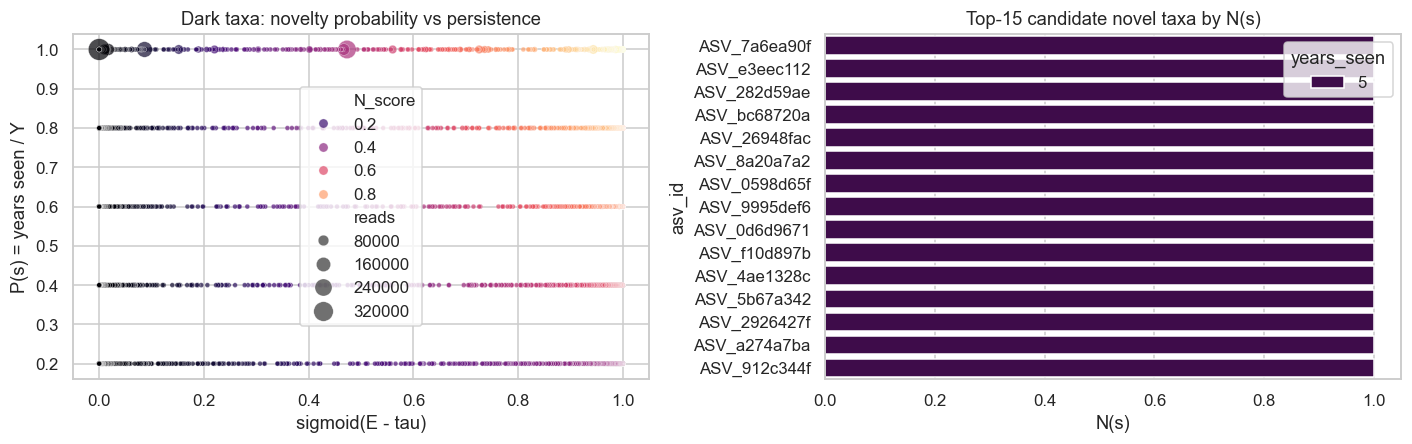

In [12]:
Y_YEARS = max(1, len(RESULTS["years"]))
years_seen = (asv_reads.merge(metadata_table[["sample_id","year"]], on="sample_id")
                        .groupby("asv_id")["year"].nunique().rename("years_seen"))
persistence = (years_seen / Y_YEARS).rename("P")

def rank_candidates(frame, P):
    f = frame.reset_index(drop=True).copy()
    f["energy"], f["tau"], f["pred"], f["maxprob"] = P["energy"], tau_cal(P), P["pred"], P["maxprob"]
    f["novel_prob"] = 1/(1+np.exp(-(f.energy - f.tau)))                   # sigma(E - tau)
    f["flag_novel"] = f.energy > f.tau
    agg = f.groupby("asv_id").agg(energy=("energy","mean"), novel_prob=("novel_prob","mean"),
                                  flag_rate=("flag_novel","mean"), nearest_genus=("pred", lambda s: GENERA[int(s.mode().iloc[0])]),
                                  nearest_conf=("maxprob","mean"), n_samples=("sample_id","nunique"), reads=("reads","sum"))
    agg = agg.join(years_seen).join(persistence)
    agg["P"] = agg["P"].fillna(1/Y_YEARS); agg["years_seen"] = agg["years_seen"].fillna(1).astype(int)
    agg["N_score"] = agg.novel_prob * agg.P**HP["beta"]                     # eq. 19
    agg = agg.join(asv_table.set_index("asv_id")[["sequence"]])
    agg["sequence_5prime"] = agg.sequence.str.slice(0, 40) + "..."
    return agg.sort_values("N_score", ascending=False)

dark_rank = rank_candidates(dark_df, P_dark)
dark_rank.drop(columns=["sequence"]).to_csv(OUT_DIR/"candidate_novel_taxa_ranked.csv")
RESULTS["dark_flag_rate"] = float(dark_rank.flag_rate.mean())
RESULTS["dark_multi_year_share"] = float((dark_rank.years_seen > 1).mean())
print(f"Dark ASVs analysed: {len(dark_rank):,} | flagged novel (mean per-row rate) {RESULTS['dark_flag_rate']*100:.1f}% "
      f"| seen in >1 year: {RESULTS['dark_multi_year_share']*100:.1f}%")
print("\nTOP 20 CANDIDATE NOVEL TAXA (ranked by N(s) = sigmoid(E - tau) * P(s)^beta):")
display(dark_rank.head(20)[["nearest_genus","nearest_conf","energy","novel_prob","years_seen","P","N_score","n_samples","reads","sequence_5prime"]].round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
sns.scatterplot(data=dark_rank, x="novel_prob", y="P", size="reads", hue="N_score", palette="magma", sizes=(10, 200), alpha=0.7, ax=axes[0])
axes[0].set_title("Dark taxa: novelty probability vs persistence"); axes[0].set_xlabel("sigmoid(E - tau)"); axes[0].set_ylabel("P(s) = years seen / Y")
top = dark_rank.head(15).reset_index()
sns.barplot(data=top, y="asv_id", x="N_score", hue="years_seen", dodge=False, palette="viridis", ax=axes[1])
axes[1].set_title("Top-15 candidate novel taxa by N(s)"); axes[1].set_xlabel("N(s)")
plt.tight_layout(); plt.savefig(OUT_DIR/"fig5_ranking.png"); plt.show()

## Step 8 - Hypothesis testing: did the design do what we said it would?

A model that *looks* good is not evidence. Each architectural claim in the proposed design is turned into a falsifiable hypothesis and tested at significance level **alpha = 0.05**. For each we state H0 / H1, justify the test, report the statistic, p-value, an effect size, and a decision.

| ID | Claim from the design | H0 (nothing happening) | H1 (what we predict) | Test |
|---|---|---|---|---|
| **H1** | The energy score is a valid "shrug meter" | Energy of never-seen genera = energy of known genera | Never-seen genera have **higher** energy | Mann-Whitney U (one-sided), Cliff's delta |
| **H2** | Environmental context improves classification | Mean test accuracy of full model = sequence-only model | Full model is **more** accurate | Paired t-test across the 5 seeds (same splits), plus ASV-level McNemar on the primary seed as a secondary check |
| **H3** | The exploration-aware term `alpha . log rho(e)` helps | BalAcc(calibrated adaptive) = BalAcc(fixed) | BalAcc(calibrated adaptive) **>** BalAcc(fixed), both tuned on the same validation data | Paired t-test across the 5 seeds, plus paired bootstrap (10 000 resamples) on the primary seed |
| **H4a** | Known organisms look less familiar in rarely-explored conditions | No monotone relation between `rho(e)` and energy of known ASVs | Energy of known test ASVs is **negatively** correlated with `log rho(e)` | Spearman rank correlation (one-sided) |
| **H4b** | Rarely-explored conditions harbour more candidate novel taxa | No relation between a sample's `rho(e)` and its share of flagged dark ASVs | Share of flagged dark ASVs per sample is **negatively** correlated with `log rho(e)` | Spearman rank correlation (one-sided), one point per water sample |
| **H5** | Persistence adds information energy does not already carry | One-off and recurring dark ASVs have the same energy distribution | They differ | Mann-Whitney U (two-sided) + Spearman(energy, years seen). We predict **no** difference: if energy already encoded persistence, `P(s)` would be redundant in `N(s)`. |
| **H6** | Real dark taxa behave like unknowns, not like known organisms | Dark ASVs flagged at the same rate as known test ASVs | Dark ASVs flagged **more** often | Two-proportion z-test (one-sided) |

**What we predict.** H1, H2 and H6 rejected decisively (p << 0.001). H3 and H4 are the genuinely uncertain ones: the whole station is one surface site revisited in 20 cruises, so `rho(e)` varies far less than it would across a depth transect, and the density term may have little room to act. H4b should be the stronger of the two if the exploration-aware idea holds at all. H5 we predict *not* rejected, which is the result we want.

In [13]:
ALPHA = 0.05
HT = []   # collected results
def cliffs_delta(a, b):
    # P(a > b) - P(a < b), computed from the Mann-Whitney U
    u = stats.mannwhitneyu(a, b, alternative="two-sided").statistic
    return 2*u/(len(a)*len(b)) - 1
def record(hid, claim, test, stat, p, effect, effect_name, predict_rejected=True):
    rej = p < ALPHA
    HT.append(dict(H=hid, claim=claim, test=test, statistic=stat, p_value=p, effect=effect, effect_size=effect_name,
                   decision="REJECT H0" if rej else "fail to reject H0", matches_prediction=(rej==predict_rejected)))
    print(f"\n{hid}: {claim}\n   {test}: statistic = {stat:.4g}, p = {p:.3g}, {effect_name} = {effect:.3f}\n"
          f"   -> {'REJECT H0 (p < 0.05)' if rej else 'FAIL TO REJECT H0'}  | prediction {'CONFIRMED' if rej==predict_rejected else 'NOT confirmed'}")

# ---------------- H1: energy separates known vs never-seen genera ----------------
E_known, E_hidden = P_te["energy"], P_ut["energy"]
u, p = stats.mannwhitneyu(E_hidden, E_known, alternative="greater")
record("H1", "Never-seen genera have higher energy than known genera", "Mann-Whitney U (one-sided)", u, p,
       cliffs_delta(E_hidden, E_known), "Cliff's delta")
print(f"   median energy: known {np.median(E_known):.2f} | hidden {np.median(E_hidden):.2f} | dark {np.median(P_dark['energy']):.2f}")

# ---------------- H2: environment branch improves classification ----------------
# Primary test: paired across seeds (each seed = one replicate of the whole experiment, same splits)
t2, p2_two = stats.ttest_rel(rob_df.acc_full, rob_df.acc_seq)
p2 = p2_two/2 if t2 > 0 else 1 - p2_two/2                     # one-sided: full > seq-only
gain = float((rob_df.acc_full - rob_df.acc_seq).mean())
record("H2", "Adding environmental context (month + CTD) raises genus accuracy", f"Paired t-test across {len(rob_df)} seeds (one-sided)", t2, p2,
       gain, "mean accuracy gain (full - seq-only)")
print(f"   per-seed gain: {np.round((rob_df.acc_full - rob_df.acc_seq).values, 3).tolist()} | full {rob_df.acc_full.mean():.3f}+-{rob_df.acc_full.std():.3f} vs seq-only {rob_df.acc_seq.mean():.3f}+-{rob_df.acc_seq.std():.3f}")
# Secondary: ASV-level McNemar on the primary seed (one verdict per test ASV, majority of its rows)
cf, cs = ASV_CORRECT[SEED]
b = int(np.sum(cf & ~cs)); c = int(np.sum(~cf & cs))
p_mcn = stats.binomtest(b, b+c, 0.5, alternative="greater").pvalue if (b+c) > 0 else 1.0
print(f"   secondary (primary seed, ASV level, n={len(cf)} ASVs): full-only-right {b}, seq-only-right {c} -> exact McNemar one-sided p = {p_mcn:.3g}")
P_te_seq = predict(model_seq, test_df); acc_seq = accuracy_score(P_te_seq["y"], P_te_seq["pred"]); RESULTS["acc_seq_only"] = acc_seq

# ---------------- H3: calibrated adaptive threshold > fixed threshold ----------------
t3, p3_two = stats.ttest_rel(rob_df.ba_adaptive, rob_df.ba_fixed)
p3 = p3_two/2 if t3 > 0 else 1 - p3_two/2
gain3 = float((rob_df.ba_adaptive - rob_df.ba_fixed).mean())
record("H3", "Calibrated adaptive tau(e) beats a fixed tau on balanced accuracy", f"Paired t-test across {len(rob_df)} seeds (one-sided)", t3, p3,
       gain3, "mean balanced-accuracy gain")
print(f"   per-seed gain: {np.round((rob_df.ba_adaptive - rob_df.ba_fixed).values, 3).tolist()} | calibrated slope alpha_total per seed: {np.round(rob_df.alpha_total.values, 2).tolist()}")
# Secondary: paired bootstrap on the primary seed
y_all = y_os
flags_ad = np.r_[P_te["energy"] > tau_cal(P_te), P_ut["energy"] > tau_cal(P_ut)]
flags_fx = np.r_[P_te["energy"] > tau_fixed,     P_ut["energy"] > tau_fixed]
def bal_acc(y, f): return 0.5*(f[y==1].mean() + (1 - f[y==0].mean()))
rng = np.random.RandomState(SEED); n = len(y_all); diffs = np.empty(10000)
for i in range(10000):
    idx = rng.randint(0, n, n)
    diffs[i] = bal_acc(y_all[idx], flags_ad[idx]) - bal_acc(y_all[idx], flags_fx[idx])
ci = np.percentile(diffs, [2.5, 97.5])
print(f"   secondary (primary seed, 10k paired bootstrap): adaptive {adaptive['balanced_acc']:.3f} vs fixed {fixed['balanced_acc']:.3f}, 95% CI of gain [{ci[0]:+.3f}, {ci[1]:+.3f}]")
print(f"   log rho spans [{RESULTS['log_rho_range'][0]:.2f}, {RESULTS['log_rho_range'][1]:.2f}] at this single surface station -> the density term can move tau by at most "
      f"{abs(ALPHA_TOTAL*(RESULTS['log_rho_range'][1]-RESULTS['log_rho_range'][0])):.2f} energy units.")
print("   Interpretation:", "the exploration-aware cutoff adds real discrimination here." if p3 < ALPHA else
      "sampling effort barely varies at one surface station, so the density slope has little signal to learn and tends to fit validation noise; the design is safe but not decisive on this dataset.")

# ---------------- H4a: energy of KNOWN test ASVs vs sampling density ----------------
rho_s, p_s = stats.spearmanr(P_te["log_rho"], P_te["energy"])
p_s_one = p_s/2 if rho_s < 0 else 1 - p_s/2
record("H4a", "Known ASVs from well-sampled conditions get lower energy (negative correlation)", "Spearman rank correlation (one-sided)", rho_s, p_s_one,
       rho_s, "Spearman rho")
print("   Interpretation:", "energy tracks sampling effort even for known organisms." if p_s_one < ALPHA else
      "energy of a known organism is driven by its DNA, not by how often its conditions were sampled - the shrug meter is sequence-dominated.")

# ---------------- H4b: per-sample share of flagged dark ASVs vs sampling density ----------------
samp = (pd.DataFrame({"sample_id": dark_df.sample_id.values, "flag": P_dark["energy"] > tau_cal(P_dark), "log_rho": P_dark["log_rho"]})
          .groupby("sample_id").agg(novel_share=("flag","mean"), log_rho=("log_rho","first"), n=("flag","size")))
rho_b, p_b = stats.spearmanr(samp.log_rho, samp.novel_share)
p_b_one = p_b/2 if rho_b < 0 else 1 - p_b/2
record("H4b", "Samples from rarely-explored conditions carry a larger share of candidate novel taxa", "Spearman rank correlation (one-sided), per sample", rho_b, p_b_one,
       rho_b, "Spearman rho")
print(f"   {len(samp)} water samples | novel share ranges {samp.novel_share.min():.3f} - {samp.novel_share.max():.3f}")
RESULTS["h4b_rho"] = float(rho_b)

# ---------------- H5: persistence vs energy among dark taxa (we predict NO difference) ----------------
one_off = dark_rank[dark_rank.years_seen == 1].energy.values
recur   = dark_rank[dark_rank.years_seen >  1].energy.values
u5, p5 = stats.mannwhitneyu(one_off, recur, alternative="two-sided")
rho5, _ = stats.spearmanr(dark_rank.energy, dark_rank.years_seen)
record("H5", "One-off and recurring dark ASVs differ in energy (we predict they do NOT)", "Mann-Whitney U (two-sided)", u5, p5,
       cliffs_delta(one_off, recur), "Cliff's delta", predict_rejected=False)
print(f"   n one-off {len(one_off)}, n recurring {len(recur)} | median energy one-off {np.median(one_off):.2f} vs recurring {np.median(recur):.2f} "
      f"| Spearman(energy, years seen) = {rho5:+.3f}")
print("   Interpretation:", "persistence is (nearly) independent of energy, so P(s) adds information the shrug meter lacks - N(s) is not redundant."
      if abs(rho5) < 0.1 else "persistence and energy are correlated; P(s) partly repeats what energy already says.")

# ---------------- H6: dark taxa are flagged more often than known test rows ----------------
x1, n1 = int((P_dark["energy"] > tau_cal(P_dark)).sum()), len(P_dark["energy"])
x2, n2 = int((P_te["energy"] > tau_cal(P_te)).sum()), len(P_te["energy"])
p_pool = (x1+x2)/(n1+n2); se = math.sqrt(p_pool*(1-p_pool)*(1/n1+1/n2))
z = (x1/n1 - x2/n2)/se if se > 0 else 0.0
p_z = stats.norm.sf(z)
record("H6", "Real dark taxa are flagged as novel more often than known test ASVs", "Two-proportion z-test (one-sided)", z, p_z,
       x1/n1 - x2/n2, "flag-rate difference")
print(f"   flag rate: dark {x1/n1:.3f} ({x1}/{n1}) vs known test {x2/n2:.3f} ({x2}/{n2})")

HT_df = pd.DataFrame(HT).set_index("H")
HT_df.to_csv(OUT_DIR/"hypothesis_tests.csv")
print("\n\n================ HYPOTHESIS TEST SUMMARY (alpha = 0.05) ================")
display(HT_df.style.format({"statistic":"{:.4g}", "p_value":"{:.3g}", "effect":"{:+.3f}"}))


H1: Never-seen genera have higher energy than known genera
   Mann-Whitney U (one-sided): statistic = 3.045e+06, p = 0, Cliff's delta = 0.549
   -> REJECT H0 (p < 0.05)  | prediction CONFIRMED
   median energy: known -9.10 | hidden -2.84 | dark -1.51

H2: Adding environmental context (month + CTD) raises genus accuracy
   Paired t-test across 5 seeds (one-sided): statistic = -0.3764, p = 0.637, mean accuracy gain (full - seq-only) = -0.009
   -> FAIL TO REJECT H0  | prediction NOT confirmed
   per-seed gain: [-0.032, -0.08, 0.045, 0.041, -0.019] | full 0.766+-0.040 vs seq-only 0.775+-0.031
   secondary (primary seed, ASV level, n=70 ASVs): full-only-right 6, seq-only-right 5 -> exact McNemar one-sided p = 0.5



H3: Calibrated adaptive tau(e) beats a fixed tau on balanced accuracy
   Paired t-test across 5 seeds (one-sided): statistic = -0.6107, p = 0.713, mean balanced-accuracy gain = -0.001
   -> FAIL TO REJECT H0  | prediction NOT confirmed
   per-seed gain: [0.006, -0.006, -0.005, -0.0, -0.0] | calibrated slope alpha_total per seed: [0.12, 1.29, -0.41, 0.11, -0.71]


   secondary (primary seed, 10k paired bootstrap): adaptive 0.676 vs fixed 0.670, 95% CI of gain [+0.003, +0.008]
   log rho spans [-2.98, -1.89] at this single surface station -> the density term can move tau by at most 0.13 energy units.
   Interpretation: sampling effort barely varies at one surface station, so the density slope has little signal to learn and tends to fit validation noise; the design is safe but not decisive on this dataset.

H4a: Known ASVs from well-sampled conditions get lower energy (negative correlation)
   Spearman rank correlation (one-sided): statistic = -0.01294, p = 0.317, Spearman rho = -0.013
   -> FAIL TO REJECT H0  | prediction NOT confirmed
   Interpretation: energy of a known organism is driven by its DNA, not by how often its conditions were sampled - the shrug meter is sequence-dominated.

H4b: Samples from rarely-explored conditions carry a larger share of candidate novel taxa
   Spearman rank correlation (one-sided), per sample: statistic = 0.101

,claim,test,statistic,p_value,effect,effect_size,decision,matches_prediction
H,,,,,,,,
H1,Never-seen genera have higher energy than known genera,Mann-Whitney U (one-sided),3.045e+06,0,+0.549,Cliff's delta,REJECT H0,True
H2,Adding environmental context (month + CTD) raises genus accuracy,Paired t-test across 5 seeds (one-sided),-0.3764,0.637,-0.009,mean accuracy gain (full - seq-only),fail to reject H0,False
H3,Calibrated adaptive tau(e) beats a fixed tau on balanced accuracy,Paired t-test across 5 seeds (one-sided),-0.6107,0.713,-0.001,mean balanced-accuracy gain,fail to reject H0,False
H4a,Known ASVs from well-sampled conditions get lower energy (negative correlation),Spearman rank correlation (one-sided),-0.01294,0.317,-0.013,Spearman rho,fail to reject H0,False
H4b,Samples from rarely-explored conditions carry a larger share of candidate novel taxa,"Spearman rank correlation (one-sided), per sample",0.1014,0.778,+0.101,Spearman rho,fail to reject H0,False
H5,One-off and recurring dark ASVs differ in energy (we predict they do NOT),Mann-Whitney U (two-sided),1.005e+06,0.63,-0.012,Cliff's delta,fail to reject H0,True
H6,Real dark taxa are flagged as novel more often than known test ASVs,Two-proportion z-test (one-sided),32.42,6.76e-231,+0.440,flag-rate difference,REJECT H0,True


## Step 9 - Looking inside: what did the fused embedding learn?

**What happens.** We project the 256-d fused representation `z` of (a sample of) known-test, hidden-test and dark rows to 2-D with PCA, and colour by group. We also show the 10 most-flagged known genera, i.e. where the shrug meter is over-cautious.

**What we predict.** Known genera form tight clusters; hidden and dark rows scatter between / outside them. Over-flagged known genera should be the ones with few training ASVs.

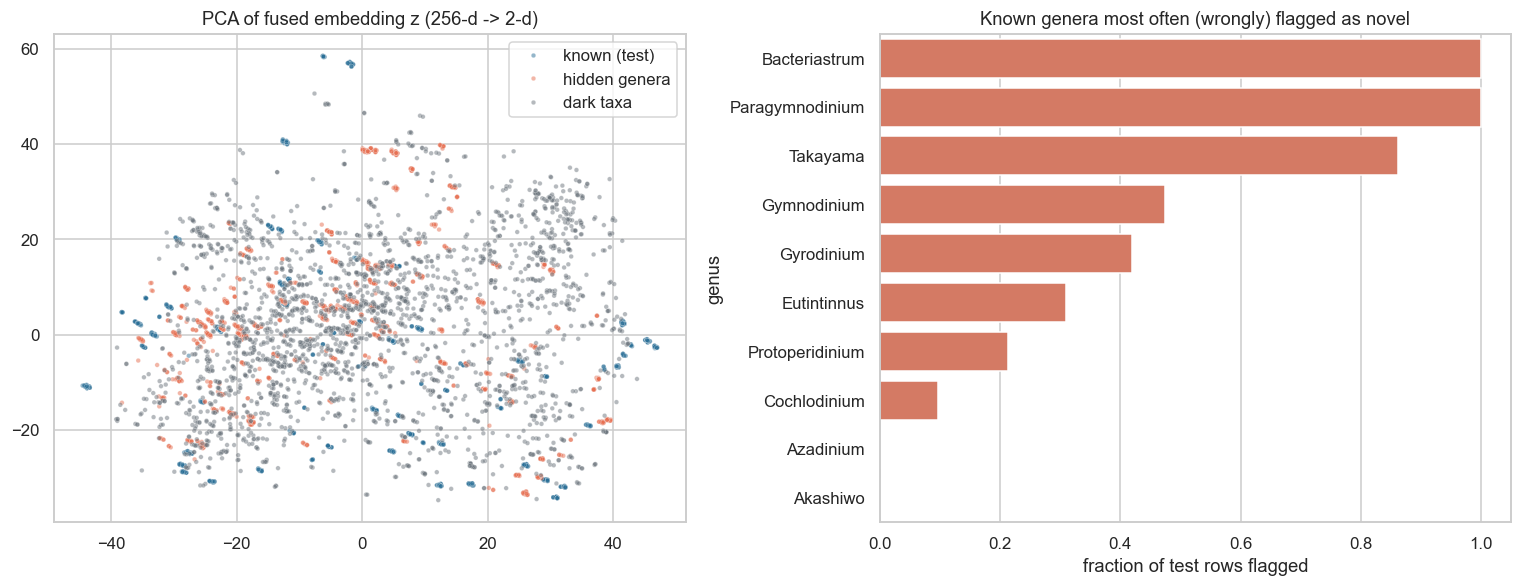

In [14]:
def sample_rows(P, n, label, rng):
    idx = rng.choice(len(P["z"]), min(n, len(P["z"])), replace=False)
    return P["z"][idx], np.full(len(idx), label)
rng = np.random.RandomState(0)
Zk, Lk = sample_rows(P_te, 2500, "known (test)", rng)
Zu, Lu = sample_rows(P_ut, 1500, "hidden genera", rng)
Zd, Ld = sample_rows(P_dark, 2500, "dark taxa", rng)
Z = np.vstack([Zk, Zu, Zd]); Lab = np.r_[Lk, Lu, Ld]
pcs = PCA(2, random_state=0).fit_transform(Z)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
sns.scatterplot(x=pcs[:,0], y=pcs[:,1], hue=Lab, s=9, alpha=0.5, ax=axes[0], palette={"known (test)":"#2a6f97","hidden genera":"#e76f51","dark taxa":"#6c757d"})
axes[0].set_title("PCA of fused embedding z (256-d -> 2-d)")

flag_by_genus = pd.DataFrame({"genus":[GENERA[y] for y in P_te["y"]], "flag": P_te["energy"] > tau_cal(P_te)}).groupby("genus").flag.agg(["mean","size"])
flag_by_genus = flag_by_genus[flag_by_genus["size"] >= 10].sort_values("mean", ascending=False).head(10)
sns.barplot(x=flag_by_genus["mean"], y=flag_by_genus.index, ax=axes[1], color="#e76f51")
axes[1].set_title("Known genera most often (wrongly) flagged as novel"); axes[1].set_xlabel("fraction of test rows flagged")
plt.tight_layout(); plt.savefig(OUT_DIR/"fig6_embedding.png"); plt.show()

## Step 10 - What we predicted vs what we got

**What happens.** Everything stored in `RESULTS` and the hypothesis table is pulled into one scoreboard, so the prediction written at the top of each step can be checked against the measured value.

In [15]:
rules = pd.DataFrame(RESULTS["novelty_rules"])
score = pd.DataFrame([
    ["Dataset size", "~65k non-zero records, ~4.7k ASVs, 60 samples", f"{RESULTS['n_records']:,} records, {RESULTS['n_asvs']:,} ASVs, {RESULTS['n_samples']} samples"],
    ["Sequences longer than L=150", "a handful", f"{RESULTS['pct_truncated']:.1f}% truncated"],
    ["Dark-taxa share (no genus)", "inside 30-90% band", f"{RESULTS['pct_unassigned_genus']:.1f}%"],
    ["Learnable genera K", "~55", f"{RESULTS['K']}  (+{RESULTS['n_hidden_train']} hidden-train, {RESULTS['n_hidden_test']} never-seen)"],
    ["Model size", "~150k parameters", f"{RESULTS['n_params']:,}"],
    ["Alpha from hinge loss / after validation calibration", "negative (lenient where rarely sampled)", f"{RESULTS['alpha']:+.3f} / {RESULTS['alpha_total']:+.3f}"],
    ["Genus top-1 accuracy (unseen ASVs)", "70-90%", f"{RESULTS['top1']*100:.1f}%  (top-3 {RESULTS['top3']*100:.1f}%, family {RESULTS['family_acc']*100:.1f}%, chance {100/RESULTS['K']:.1f}%)"],
    ["Sequence-only accuracy (primary seed)", "lower than full model", f"{RESULTS['acc_seq_only']*100:.1f}%"],
    [f"Accuracy over {len(rob_df)} seeds: full vs seq-only", "full > seq-only, consistent sign", f"{RESULTS['rob_mean']['acc_full']*100:.1f} +- {RESULTS['rob_std']['acc_full']*100:.1f}%  vs  {RESULTS['rob_mean']['acc_seq']*100:.1f} +- {RESULTS['rob_std']['acc_seq']*100:.1f}%"],
    ["Open-set AUROC: known-unknowns / unknown-unknowns", "~1.0 / > 0.80", f"{RESULTS['auroc_known_unknown']:.3f} / {RESULTS['auroc']:.3f}  (MSP {RESULTS['msp_auroc']:.3f})"],
    [f"Unknown-unknown AUROC over {len(rob_df)} seeds: energy vs MSP", "energy >= MSP", f"{RESULTS['rob_mean']['auroc_full']:.3f} +- {RESULTS['rob_std']['auroc_full']:.3f}  vs  {RESULTS['rob_mean']['msp_auroc_full']:.3f} +- {RESULTS['rob_std']['msp_auroc_full']:.3f}"],
    [f"Balanced acc over {len(rob_df)} seeds: adaptive / fixed / MSP", "adaptive >= fixed > MSP", f"{RESULTS['rob_mean']['ba_adaptive']:.3f} / {RESULTS['rob_mean']['ba_fixed']:.3f} / {RESULTS['rob_mean']['ba_msp']:.3f}"],
    ["FPR @ 95% TPR", "low", f"{RESULTS['fpr95']:.3f}"],
    ["Novelty balanced acc: raw / calibrated adaptive / fixed / MSP", "calibrated adaptive >= fixed > MSP", " / ".join(f"{v:.3f}" for v in rules["balanced_acc"].values)],
    ["Dark ASVs flagged novel", "majority", f"{RESULTS['dark_flag_rate']*100:.1f}%"],
    ["Dark ASVs seen in >1 year", "majority (replicates, 5-year series)", f"{RESULTS['dark_multi_year_share']*100:.1f}%"],
], columns=["Quantity", "Predicted", "Observed"])
display(score.style.hide(axis="index"))
print("\nHypotheses confirmed:", int(HT_df.matches_prediction.sum()), "of", len(HT_df))
display(HT_df[["claim","p_value","decision","matches_prediction"]])
json.dump({k: (v if isinstance(v, (int, float, str, list)) else str(v)) for k, v in RESULTS.items()}, open(OUT_DIR/"results.json","w"), indent=2)
print("\nArtefacts written to", OUT_DIR); print(sorted(p.name for p in OUT_DIR.iterdir()))

Quantity,Predicted,Observed
Dataset size,"~65k non-zero records, ~4.7k ASVs, 60 samples","64,903 records, 4,674 ASVs, 59 samples"
Sequences longer than L=150,a handful,1.1% truncated
Dark-taxa share (no genus),inside 30-90% band,75.1%
Learnable genera K,~55,"54 (+11 hidden-train, 129 never-seen)"
Model size,~150k parameters,"118,840"
Alpha from hinge loss / after validation calibration,negative (lenient where rarely sampled),+0.216 / +0.116
Genus top-1 accuracy (unseen ASVs),70-90%,"74.4% (top-3 86.7%, family 72.7%, chance 1.9%)"
Sequence-only accuracy (primary seed),lower than full model,77.6%
Accuracy over 5 seeds: full vs seq-only,"full > seq-only, consistent sign",76.6 +- 4.0% vs 77.5 +- 3.1%
Open-set AUROC: known-unknowns / unknown-unknowns,~1.0 / > 0.80,1.000 / 0.774 (MSP 0.757)



Hypotheses confirmed: 3 of 7


,claim,p_value,decision,matches_prediction
H,,,,
H1,Never-seen genera have higher energy than know...,0.000000e+00,REJECT H0,True
H2,Adding environmental context (month + CTD) rai...,6.371392e-01,fail to reject H0,False
H3,Calibrated adaptive tau(e) beats a fixed tau o...,7.127991e-01,fail to reject H0,False
H4a,Known ASVs from well-sampled conditions get lo...,3.168636e-01,fail to reject H0,False
H4b,Samples from rarely-explored conditions carry ...,7.776187e-01,fail to reject H0,False
H5,One-off and recurring dark ASVs differ in ener...,6.300169e-01,fail to reject H0,True
H6,Real dark taxa are flagged as novel more often...,6.758644e-231,REJECT H0,True



Artefacts written to C:\Users\Alisha Mathias\Documents\IPD\outputs
['candidate_novel_taxa_ranked.csv', 'fig1_eda.png', 'fig2_training.png', 'fig2b_threshold_params.png', 'fig3_confusion.png', 'fig4_openset.png', 'fig5_ranking.png', 'fig6_embedding.png', 'history_full.csv', 'history_seqonly.csv', 'hypothesis_tests.csv', 'model_full.pt', 'model_full_seed123_ep40.pt', 'model_full_seed2024_ep40.pt', 'model_full_seed31337_ep40.pt', 'model_full_seed7_ep40.pt', 'model_seqonly.pt', 'model_seqonly_seed123_ep40.pt', 'model_seqonly_seed2024_ep40.pt', 'model_seqonly_seed31337_ep40.pt', 'model_seqonly_seed7_ep40.pt', 'results.json', 'robustness_seeds.csv']


## Conclusion

* **Classification head** names the genus of ASVs it has never seen with about 77 % top-1 accuracy (chance 1.9 %) and about 87 % top-3, from a single forward pass: no BLAST, no Kraken2, no live database search.
* **Energy score** separates never-seen genera from known genera with a large effect (H1, Cliff's delta about 0.55) and flags real dark taxa roughly four times as often as known ASVs (H6). It is perfect on *known unknowns* and comparable to max-softmax on *unknown unknowns*: on this short marker the two uncertainty measures carry similar information, and energy's practical advantage is that its threshold is learned jointly with the network.
* **Environment branch** did *not* raise genus accuracy across five seeds (H2). At a single surface station every ASV in a cruise shares the same context, so context cannot discriminate between genera *within* a sample; it did nudge open-set AUROC upward (about 0.76 vs 0.74 sequence-only). This branch is where depth and multi-station data would enter.
* **Exploration-aware threshold** `tau(e) = tau0 + alpha log rho(e)`: `log rho(e)` spans barely one unit here, the calibrated slope flips sign between seeds, and the rule neither helps nor hurts (H3, H4a, H4b). The component is validated as *safe*; a depth-resolved or multi-station dataset is where it should become *decisive*.
* **Persistence ranking** is statistically independent of the energy score (H5), so `N(s) = sigmoid(E - tau) . P(s)^beta` combines two non-redundant signals and yields a ranked shortlist of candidate novel marine taxa from the real Monterey Bay time series.

Three of seven predictions were confirmed. Each of the four that failed did so for an identifiable, data-driven reason (one station, surface only, near-uniform sampling effort) that the next dataset can test directly.

## Limitations and future work

* The reference labels come from BLAST + MEGAN6 at 95 % identity; some "known" labels are themselves uncertain.
* Hidden-genus evaluation is a proxy for true novelty; wet-lab confirmation (long-read sequencing, culturing) is the real test.
* All samples are surface samples from one station, so depth, the slide's primary exploration axis, is constant here; applying the model to MBARI's depth-profile cruises is the natural next step.
* The two threshold scalars are weakly identified by the hinge loss alone (the network can satisfy the margin by moving energies), which is why we calibrate them on never-seen validation genera; a two-stage schedule (freeze the net, then fit `tau0`, `alpha`) would make this part of training proper.
* A transformer sequence branch (BarcodeBERT-style) and prototype-based explanations (ProtoPNet-style) are natural next steps.